# Business Lens and Analysis Objectives

Our selected lens is **Feature-Importance Analysis**. We investigate which original morphological
measurements contribute to distinguishing Cammeo from Osmancik rice grains, and whether a smaller
measurement subset can maintain acceptable classification performance.

**Objectives**
- Identify important original measurements.
- Investigate overlapping information between correlated measurements.
- Compare full and reduced measurement sets.
- Recommend a measurement subset supported by validation evidence.

**Notebook structure:** business question → original-feature analysis → model comparison →
importance and stability → reduced-subset experiments → final evaluation → engineered-feature
comparison experiment → answer to the business lens.

##Loading the dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


* Datasource is in .arff file which can't be loaded directly.
  - So, scipy library will be used to read the data source

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

DATA_DIR = '/content/drive/MyDrive/Y3S1ML'
FILE_PATH = os.path.join(DATA_DIR, 'Rice_Cammeo_Osmancik.arff')

print(os.listdir(DATA_DIR))
print("File exists:", os.path.exists(FILE_PATH))

['Rice_Cammeo_Osmancik.arff', 'Citation_Request.txt', 'Y3S1ML_test.ipynb', 'Copy_of_Y3S1_ML_Group_Assignment.ipynb', 'Copy_of_Y3S1_ML_Group_Assignment__7_.ipynb']
File exists: True


In [3]:
data, meta = arff.loadarff(FILE_PATH)
df = pd.DataFrame(data)

# ARFF nominal attributes load as bytes (b'Cammeo'), so decode them to strings
for col in df.select_dtypes(include=[object]).columns:
    df[col] = df[col].str.decode('utf-8')

print("Loaded successfully.")

Loaded successfully.


Metadata Exploration

In [4]:
print("Relation:", meta.name)
print("Attributes (name, type):")
for name in meta.names():
    print(f"  {name:<20} {meta[name]}")

Relation: Rice_Cammeo_Osmancik
Attributes (name, type):
  Area                 ('numeric', None)
  Perimeter            ('numeric', None)
  Major_Axis_Length    ('numeric', None)
  Minor_Axis_Length    ('numeric', None)
  Eccentricity         ('numeric', None)
  Convex_Area          ('numeric', None)
  Extent               ('numeric', None)
  Class                ('nominal', ('Cammeo', 'Osmancik'))


##Dataset observations

In [5]:
print("Shape:", df.shape)
df.head(10)

Shape: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0000,525.5790,229.7499,85.0938,0.9289,15617.0000,0.5729,Cammeo
1,14656.0000,494.3110,206.0201,91.7310,0.8954,15072.0000,0.6154,Cammeo
2,14634.0000,501.1220,214.1068,87.7683,0.9121,14954.0000,0.6933,Cammeo
3,13176.0000,458.3430,193.3374,87.4484,0.8919,13368.0000,0.6407,Cammeo
4,14688.0000,507.1670,211.7434,89.3125,0.9067,15262.0000,0.6460,Cammeo
5,13479.0000,477.0160,200.0531,86.6503,0.9013,13786.0000,0.6579,Cammeo
6,15757.0000,509.2810,207.2967,98.3361,0.8803,16150.0000,0.5897,Cammeo
7,16405.0000,526.5700,221.6125,95.4367,0.9025,16837.0000,0.6589,Cammeo
8,14534.0000,483.6410,196.6508,95.0507,0.8754,14932.0000,0.6497,Cammeo
9,13485.0000,471.5700,198.2726,87.7273,0.8968,13734.0000,0.5723,Cammeo


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(7), object(1)
memory usage: 238.3+ KB


In [7]:
df.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000
mean,12667.7276,454.2392,188.7762,86.3138,0.8869,12952.4969,0.6619
std,1732.3677,35.5971,17.4487,5.7298,0.0208,1776.9720,0.0772
min,7551.0000,359.1000,145.2645,59.5324,0.7772,7723.0000,0.4974
25%,11370.5000,426.1448,174.3539,82.7317,0.8724,11626.2500,0.5989
50%,12421.5000,448.8525,185.8101,86.4346,0.8891,12706.5000,0.6454
75%,13950.0000,483.6837,203.5504,90.1437,0.9026,14284.0000,0.7266
max,18913.0000,548.4460,239.0105,107.5424,0.9480,19099.0000,0.8610


In [8]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64

Duplicate rows: 0


Target column: Class
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64

Proportions:
Class
Osmancik   0.5722
Cammeo     0.4278
Name: proportion, dtype: float64


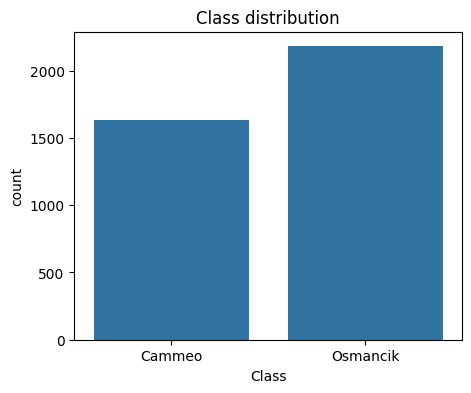

In [9]:
target_col = df.columns[-1]
print("Target column:", target_col)

counts = df[target_col].value_counts()
print(counts)
print("\nProportions:")
print(df[target_col].value_counts(normalize=True))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=target_col)
plt.title('Class distribution')
plt.show()

In [10]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

original_features = ["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length",
                     "Eccentricity", "Convex_Area", "Extent"]
orig_features = original_features          # alias used by the later comparison cells

le = LabelEncoder()
y_all = le.fit_transform(df[target_col])
print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))   # Cammeo 0, Osmancik 1

# Same arguments as the original split, so exactly the same rows land in train and test
train_idx, test_idx, y_train, y_test = train_test_split(
    df.index, y_all, test_size=0.20, stratify=y_all, random_state=42
)

df_train = df.loc[train_idx].copy()     # rows used for EDA and every development decision
df_test  = df.loc[test_idx].copy()      # held out: no development decision uses these rows

X_orig_train = df_train[original_features]
X_orig_test  = df_test[original_features]
print("Train:", X_orig_train.shape, "| Test:", X_orig_test.shape)

Class mapping: {'Cammeo': np.int64(0), 'Osmancik': np.int64(1)}
Train: (3048, 7) | Test: (762, 7)


In [11]:
# Integrity checks (keep these)
assert len(set(train_idx) & set(test_idx)) == 0, "train/test overlap"
assert len(train_idx) + len(test_idx) == len(df), "rows lost in the split"
assert (le.inverse_transform(y_train) == df.loc[train_idx, target_col].values).all(), "train labels misaligned"
assert (le.inverse_transform(y_test)  == df.loc[test_idx,  target_col].values).all(), "test labels misaligned"

pd.DataFrame({'Overall': np.bincount(y_all) / len(y_all),
              'Train':   np.bincount(y_train) / len(y_train),
              'Test':    np.bincount(y_test) / len(y_test)}, index=le.classes_).round(4)

,Overall,Train,Test
Cammeo,0.4278,0.4278,0.4278
Osmancik,0.5722,0.5722,0.5722


**Split and limitation.** The stratified 80/20 split is created before any data-informed decision;
the same rows are used by every feature-set experiment. Earlier experiments in this project had
already inspected test-set results, so the test set is not completely untouched. All new development
decisions (feature choices, tuning, model and subset selection) use training data and stratified
cross-validation only. The final test evaluation is therefore reported as a limitation-aware check,
and new external data would give stronger confirmation.

## Data dictionary (original measurements)
| Measurement | Meaning |
|---|---|
| Area | Number of pixels inside the grain boundary |
| Perimeter | Length of the grain boundary (distance between boundary pixels) |
| Major_Axis_Length | Length of the longest line that can be drawn across the grain |
| Minor_Axis_Length | Length of the shortest line that can be drawn across the grain |
| Eccentricity | How elongated the ellipse with the same moments as the grain is (0 = circle) |
| Convex_Area | Pixel count of the smallest convex shell enclosing the grain |
| Extent | Grain area divided by the area of its bounding box |

## Engineered predictors and the original measurements they need
| Engineered predictor | Original measurements needed |
|---|---|
| Perimeter_Area_Ratio | Perimeter and Area |
| Area_Axis_Product_Ratio | Area, Major_Axis_Length, Minor_Axis_Length |
| Aspect_Ratio | Major_Axis_Length and Minor_Axis_Length |
| Solidity | Area and Convex_Area |
| Circularity (4πA/P²) | Area and Perimeter |

*Fewer model predictors does not mean fewer measurements: the four engineered predictors still
require six of the seven original measurements.*

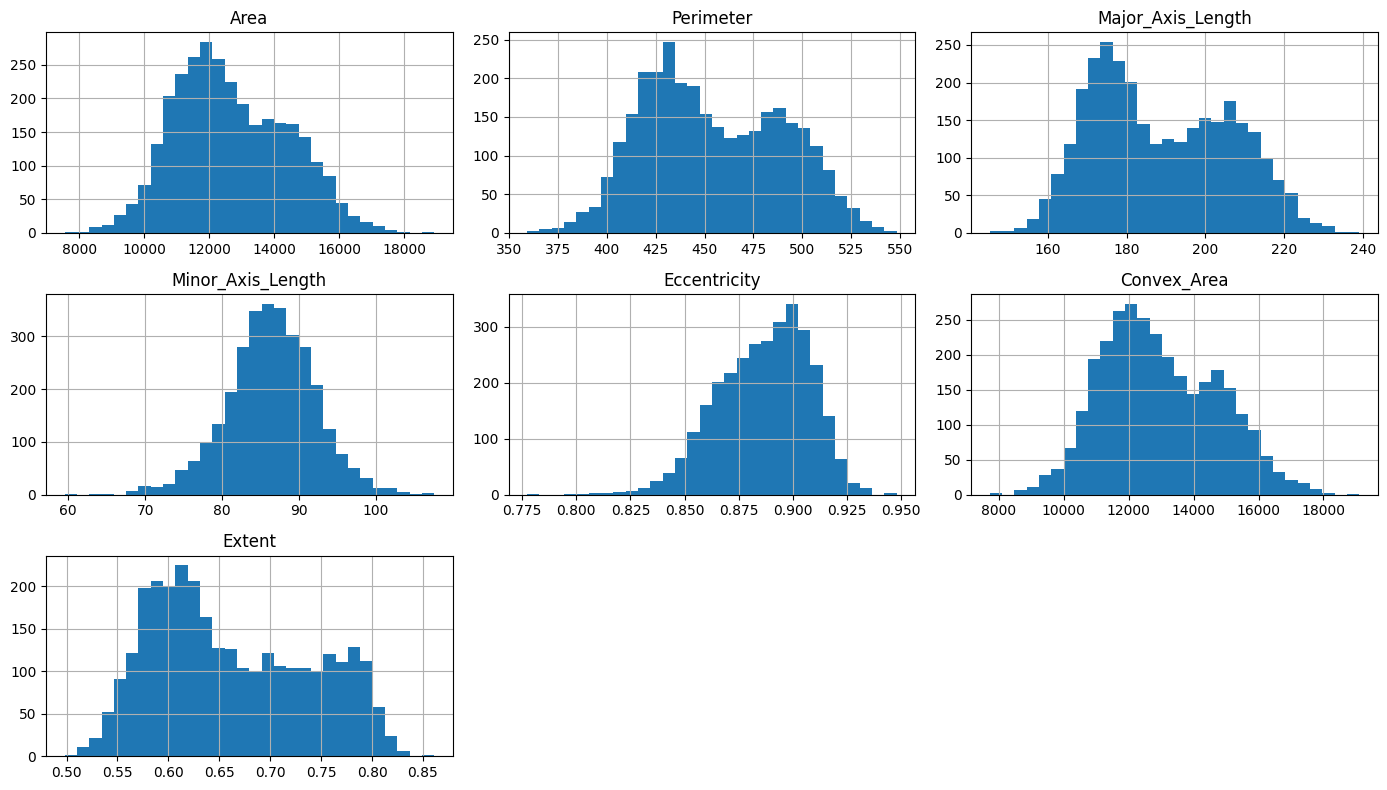

In [12]:
features = df.drop(columns=[target_col]).columns

df_train[features].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

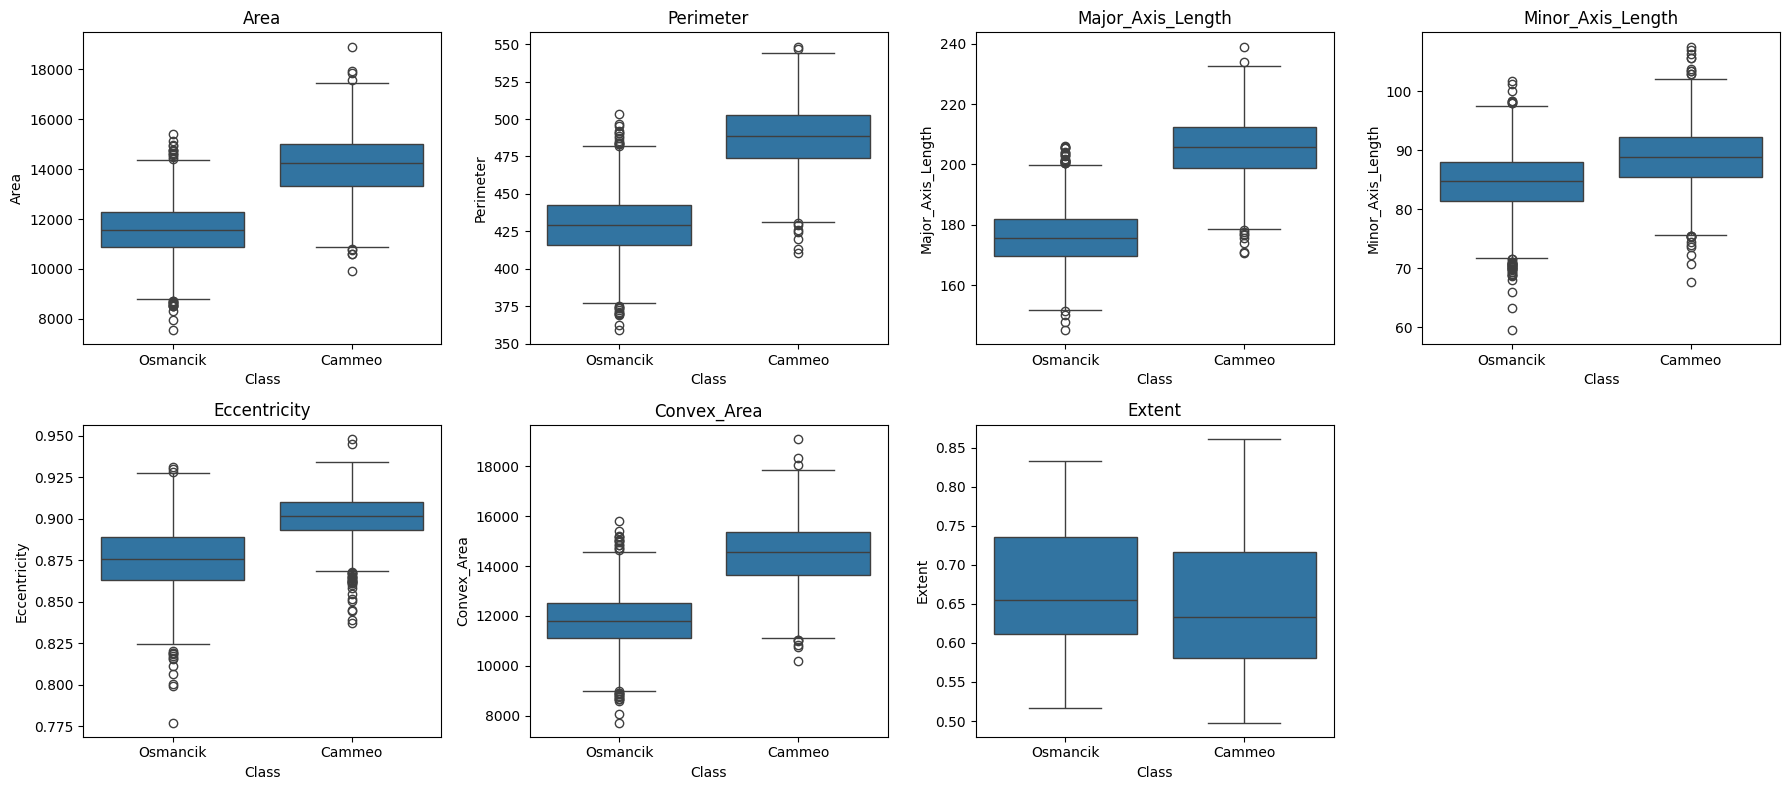

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(data=df_train, x=target_col, y=col, ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplot
for j in range(len(features), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

#Major Dataset Observations


* Clean Dataset
  - 3,810 rows × 8 columns
  - No Nulls
  - No Duplicates
  - 7 numeric features and 1 categorical feature

* Class balance
  - 57% for Osmancik, 43% for Cammeo.
  - Mildly imbalanced

* Scale differences between features
  - Scaling is useful for Logistic Regression, KNN and SVM (distance / margin / gradient based); Random Forest does not require it

* Class separation (boxplots), the most important finding
  - Strongly discriminative: Area, Perimeter, Major_Axis_Length, Convex_Area
  - Weakly discriminative: Extent

* Outliers
  - Outliers appear in almost every feature

##Checking out the correlation among the features

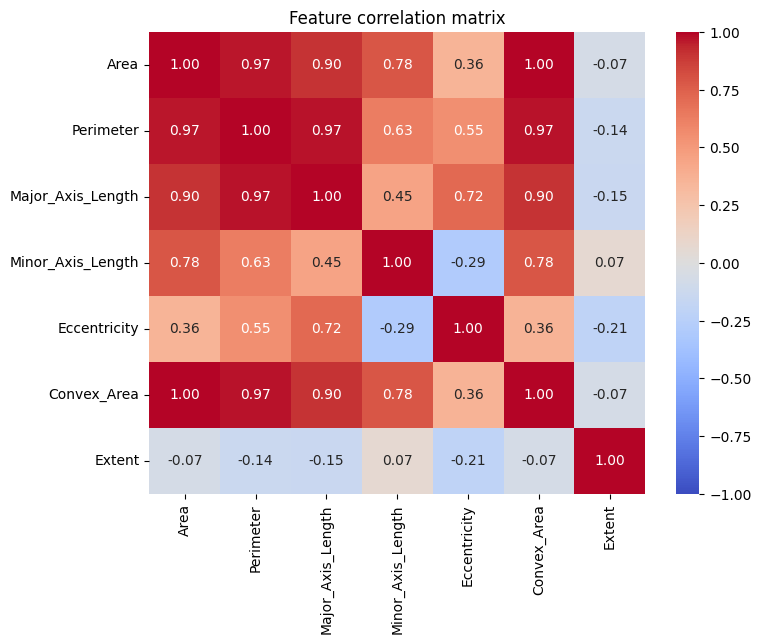

In [14]:
corr = df_train[features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature correlation matrix')
plt.show()

* Area and Convex_Area: r ≈ 1.00 (rounded). Different measurements, but very highly correlated.
* Many features are highly correlated


## Step 5 – Correlations among the original measurements (training rows)

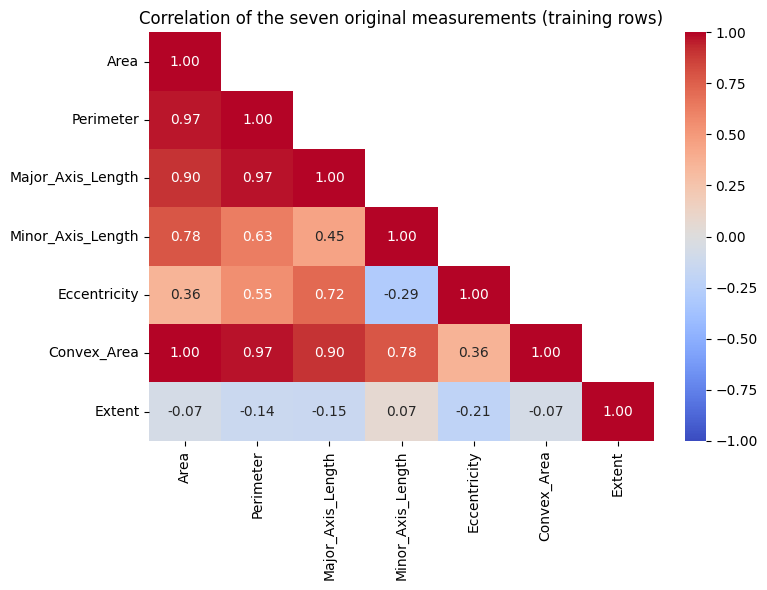

In [15]:
corr_orig = X_orig_train.corr()
upper = np.triu(np.ones_like(corr_orig, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_orig, mask=upper, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation of the seven original measurements (training rows)")
plt.tight_layout(); plt.show()

In [16]:
# Precise values for strongly related pairs (|r| >= 0.80)
lower = ~upper & ~np.eye(len(corr_orig), dtype=bool)
pairs = (corr_orig.where(lower).stack().rename('r').reset_index()
         .rename(columns={'level_0': 'Measurement A', 'level_1': 'Measurement B'}))
pairs['|r|'] = pairs['r'].abs()

strong_pairs = pairs[pairs['|r|'] >= 0.80].sort_values('|r|', ascending=False)
strong_pairs.round(5).reset_index(drop=True)

,Measurement A,Measurement B,r,|r|
0,Convex_Area,Area,0.9989,0.9989
1,Major_Axis_Length,Perimeter,0.9720,0.9720
2,Convex_Area,Perimeter,0.9701,0.9701
3,Perimeter,Area,0.9667,0.9667
4,Convex_Area,Major_Axis_Length,0.9033,0.9033
5,Major_Axis_Length,Area,0.9031,0.9031


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

_Xv = add_constant(X_orig_train)
vif_orig = pd.Series(
    [variance_inflation_factor(_Xv.values, i + 1) for i in range(len(original_features))],
    index=original_features, name='VIF'
).sort_values(ascending=False)
vif_orig.round(1)      # supporting evidence only; it does not decide the recommendation

,VIF
Area,1151.9000
Convex_Area,1034.4000
Major_Axis_Length,373.2000
Perimeter,239.9000
Minor_Axis_Length,177.1000
Eccentricity,50.2000
Extent,1.1000


In [18]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

CORR_THRESHOLD = 0.90     # measurements with |r| >= 0.90 (average linkage) are treated as one group

dist = 1 - corr_orig.abs().values
np.fill_diagonal(dist, 0)
labels = fcluster(linkage(squareform(dist, checks=False), method='average'),
                  t=1 - CORR_THRESHOLD, criterion='distance')

_tmp = {}
for feat, g in zip(corr_orig.index, labels):
    _tmp.setdefault(g, []).append(feat)
corr_groups = {f"Group {i + 1}": members for i, members in enumerate(_tmp.values())}

for name, members in corr_groups.items():
    print(f"{name}: {members}")

Group 1: ['Area', 'Perimeter', 'Major_Axis_Length', 'Convex_Area']
Group 2: ['Minor_Axis_Length']
Group 3: ['Eccentricity']
Group 4: ['Extent']


**Correlation findings.** __ and __ (r = __) share size information; __ and __ share shape information.
Area and Convex_Area contain strongly overlapping information, so their individual importance may be
shared; feature-removal experiments are needed before recommending that either be omitted.
VIF is used as supporting evidence only and does not decide the recommendation.

## Model-selection metric and acceptance rule
**Primary metric: macro-F1** (gives Cammeo and Osmancik equal weight). Also reported: accuracy, balanced
accuracy, recall for each variety, ROC-AUC and the confusion matrix.

**Tolerance (a project assumption, not a business requirement):** a reduced subset is acceptable if its
macro-F1 is at most **1.0 percentage point** below the full seven-measurement model of the same algorithm.
A subset is also flagged if either variety's recall falls by more than **2.0 points**.
Justification: __ (e.g., comparable to the fold-to-fold SD of macro-F1).

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

PRIMARY_METRIC = 'f1_macro'
TOLERANCE_PP   = 1.0    # project assumption: accept a macro-F1 loss of at most 1 percentage point
RECALL_DROP_PP = 2.0    # project assumption: flag a subset if either variety's recall falls by more than this

SCORING = {
    'f1_macro':          'f1_macro',
    'accuracy':          'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'recall_cammeo':     make_scorer(recall_score, pos_label=0),
    'recall_osmancik':   make_scorer(recall_score, pos_label=1),
    'roc_auc':           'roc_auc',
}

## Step 7 – Tune the full seven-measurement models (Pipeline + stratified CV, macro-F1)

In [20]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

ALGOS = {
    'Logistic Regression': dict(
        model=lambda: LogisticRegression(max_iter=2000, random_state=42),
        grid={'model__C': [0.01, 0.1, 1, 10, 100]}, scale=True),
    'Random Forest': dict(
        model=lambda: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
        grid={'model__max_depth': [None, 5, 10, 15], 'model__min_samples_leaf': [1, 3, 5, 10]}, scale=False),
    'KNN': dict(
        model=lambda: KNeighborsClassifier(),
        grid={'model__n_neighbors': list(range(1, 32, 2))}, scale=True),
    'SVM (RBF)': dict(
        model=lambda: SVC(kernel='rbf', random_state=42),
        grid={'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.01, 0.1, 1]}, scale=True),
}

def make_search(algo, cols=None):
    """Preprocessing + model in one Pipeline, tuned on macro-F1 with stratified CV.
    Scaling is applied to LR / KNN / SVM; Random Forest uses the raw measurements."""
    spec = ALGOS[algo]
    prep = RobustScaler() if spec['scale'] else 'passthrough'
    pipe = Pipeline([('prep', prep), ('model', spec['model']())])
    return GridSearchCV(pipe, spec['grid'], cv=cv, scoring=SCORING, refit=PRIMARY_METRIC,
                        n_jobs=None if algo == 'Random Forest' else -1)

In [21]:
import time

full_search = {}
for algo in ALGOS:
    t0 = time.time()
    full_search[algo] = make_search(algo).fit(X_orig_train[original_features], y_train)
    gs = full_search[algo]
    print(f"{algo:<20} best macro-F1 = {gs.best_score_:.4f} | {gs.best_params_} | {time.time() - t0:.0f}s")

Logistic Regression  best macro-F1 = 0.9330 | {'model__C': 100} | 2s
Random Forest        best macro-F1 = 0.9279 | {'model__max_depth': 5, 'model__min_samples_leaf': 10} | 90s
KNN                  best macro-F1 = 0.9293 | {'model__n_neighbors': 27} | 2s
SVM (RBF)            best macro-F1 = 0.9327 | {'model__C': 10, 'model__gamma': 'scale'} | 7s


## Step 8 – Compare the full-feature models

In [22]:
from sklearn.dummy import DummyClassifier

def summarize_search(gs):
    i, r = gs.best_index_, gs.cv_results_
    return {
        'CV macro-F1': r['mean_test_f1_macro'][i], 'CV macro-F1 SD': r['std_test_f1_macro'][i],
        'CV accuracy': r['mean_test_accuracy'][i], 'CV balanced acc': r['mean_test_balanced_accuracy'][i],
        'CV recall Cammeo': r['mean_test_recall_cammeo'][i], 'CV recall Osmancik': r['mean_test_recall_osmancik'][i],
        'CV ROC-AUC': r['mean_test_roc_auc'][i],
        'Best parameters': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
    }

rows = [{'Model': a, **summarize_search(gs)} for a, gs in full_search.items()]

_d = cross_validate(DummyClassifier(strategy='prior'), X_orig_train[original_features], y_train, cv=cv, scoring=SCORING)
rows.append({'Model': 'Dummy (majority)',
             'CV macro-F1': _d['test_f1_macro'].mean(), 'CV macro-F1 SD': _d['test_f1_macro'].std(),
             'CV accuracy': _d['test_accuracy'].mean(), 'CV balanced acc': _d['test_balanced_accuracy'].mean(),
             'CV recall Cammeo': _d['test_recall_cammeo'].mean(), 'CV recall Osmancik': _d['test_recall_osmancik'].mean(),
             'CV ROC-AUC': _d['test_roc_auc'].mean(), 'Best parameters': '-'})

full_table = pd.DataFrame(rows).set_index('Model').sort_values('CV macro-F1', ascending=False)
full_table.round(4)

,CV macro-F1,CV macro-F1 SD,CV accuracy,CV balanced acc,CV recall Cammeo,CV recall Osmancik,CV ROC-AUC,Best parameters
Model,,,,,,,,
Logistic Regression,0.9330,0.0084,0.9344,0.9327,0.9210,0.9444,0.9803,{'C': 100}
SVM (RBF),0.9327,0.0109,0.9341,0.9327,0.9233,0.9421,0.9597,"{'C': 10, 'gamma': 'scale'}"
KNN,0.9293,0.0101,0.9308,0.9294,0.9202,0.9387,0.9742,{'n_neighbors': 27}
Random Forest,0.9279,0.0126,0.9295,0.9276,0.9149,0.9404,0.9783,"{'max_depth': 5, 'min_samples_leaf': 10}"
Dummy (majority),0.3639,0.0002,0.5722,0.5000,0.0000,1.0000,0.5000,-


**Model selection.** Selected: __ because of its CV macro-F1 (__ ± __), consistency across folds and
practical interpretability. Hyperparameter-selection scores are *selection scores*, not independent
performance estimates; differences smaller than the fold SD are not treated as meaningful.

In [23]:
# OPTIONAL: independent estimate of the whole tuning procedure (nested CV). Slow; run for one algorithm.
from sklearn.model_selection import cross_val_score

NESTED_ALGO = 'Logistic Regression'          # any key of ALGOS
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
nested = cross_val_score(make_search(NESTED_ALGO), X_orig_train[original_features], y_train,
                         cv=outer, scoring='f1_macro')
print(f"{NESTED_ALGO}: nested-CV macro-F1 = {nested.mean():.4f} ± {nested.std():.4f}")

Logistic Regression: nested-CV macro-F1 = 0.9319 ± 0.0059


## Step 9 – Importance of the seven original measurements

,Coefficient,|Coefficient|,Coefficient rank
Convex_Area,-20.0062,20.0062,1.0000
Area,10.4286,10.4286,2.0000
Perimeter,2.9789,2.9789,3.0000
Minor_Axis_Length,2.2045,2.2045,4.0000
Major_Axis_Length,-1.5938,1.5938,5.0000
Eccentricity,-1.4706,1.4706,6.0000
Extent,0.0955,0.0955,7.0000


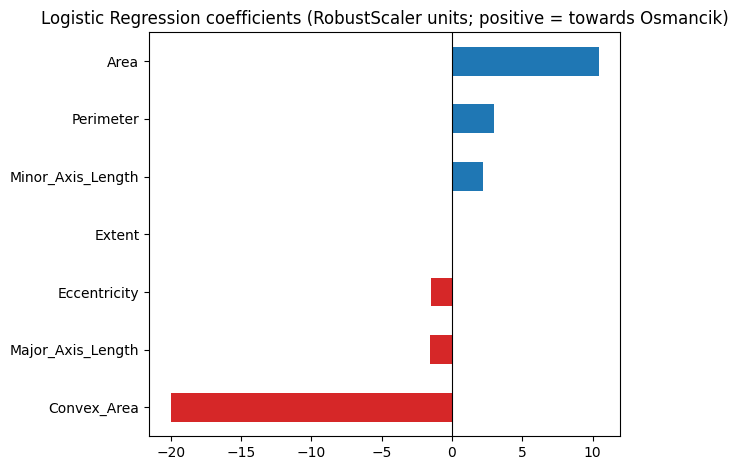

In [24]:
SELECTED_ALGO = 'Random Forest'     # <- set from the Step 8 decision (macro-F1, consistency, interpretability)

lr_pipe = full_search['Logistic Regression'].best_estimator_
coef = pd.Series(lr_pipe.named_steps['model'].coef_[0], index=original_features)

coef_table = pd.DataFrame({'Coefficient': coef, '|Coefficient|': coef.abs()})
coef_table['Coefficient rank'] = coef_table['|Coefficient|'].rank(ascending=False)
display(coef_table.sort_values('Coefficient rank').round(4))

coef.sort_values().plot(kind='barh', color=['tab:red' if v < 0 else 'tab:blue' for v in coef.sort_values()])
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Logistic Regression coefficients (RobustScaler units; positive = towards Osmancik)")
plt.tight_layout(); plt.show()

,Impurity importance,RF rank
Major_Axis_Length,0.3400,1.0000
Perimeter,0.2721,2.0000
Area,0.1586,3.0000
Convex_Area,0.1419,4.0000
Eccentricity,0.0649,5.0000
Minor_Axis_Length,0.0174,6.0000
Extent,0.0050,7.0000


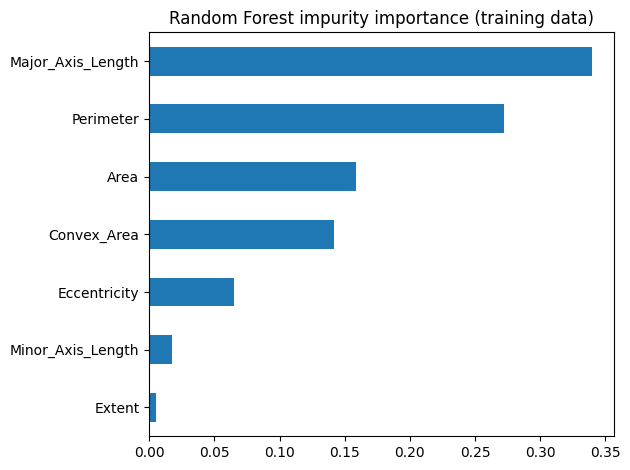

In [25]:
rf_pipe = full_search['Random Forest'].best_estimator_
rf_imp = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=original_features)

rf_table = pd.DataFrame({'Impurity importance': rf_imp, 'RF rank': rf_imp.rank(ascending=False)})
display(rf_table.sort_values('RF rank').round(4))

rf_imp.sort_values().plot(kind='barh')
plt.title("Random Forest impurity importance (training data)")
plt.tight_layout(); plt.show()

In [26]:
from sklearn.inspection import permutation_importance

def foldwise_permutation(algo, cols=original_features, n_repeats=10, retune=False):
    """Per fold: fit preprocessing + model on the fold's training rows, then measure the
    macro-F1 drop on the held-out validation rows. retune=True re-tunes inside every fold."""
    imp = []
    for k, (tr, va) in enumerate(cv.split(X_orig_train[cols], y_train), 1):
        Xtr, ytr = X_orig_train[cols].iloc[tr], y_train[tr]
        Xva, yva = X_orig_train[cols].iloc[va], y_train[va]
        pipe = make_search(algo).fit(Xtr, ytr).best_estimator_ if retune else clone(full_search[algo].best_estimator_).fit(Xtr, ytr)
        r = permutation_importance(pipe, Xva, yva, scoring='f1_macro', n_repeats=n_repeats,
                                   random_state=42, n_jobs=-1)
        imp.append(pd.Series(r.importances_mean, index=cols, name=f'Fold {k}'))
    imp = pd.DataFrame(imp)
    return imp, imp.rank(axis=1, ascending=False)

orig_perm_folds = {a: foldwise_permutation(a) for a in ALGOS}

,Logistic Regression,Random Forest,KNN,SVM (RBF)
Area,0.0895,0.0009,0.0190,0.0212
Perimeter,0.0206,0.0066,0.0246,0.0177
Major_Axis_Length,0.0247,0.0400,0.0254,0.0195
Minor_Axis_Length,0.0748,0.0007,0.0013,0.0113
Eccentricity,0.0100,0.0030,0.0533,0.0469
Convex_Area,0.5703,0.0014,0.0244,0.4095
Extent,-0.0004,-0.0000,0.0043,0.0034


,Logistic Regression,Random Forest,KNN,SVM (RBF)
Area,0.0205,0.0026,0.0065,0.0102
Perimeter,0.0102,0.0065,0.0063,0.0044
Major_Axis_Length,0.0340,0.0129,0.0072,0.0071
Minor_Axis_Length,0.0408,0.0015,0.0030,0.0070
Eccentricity,0.0126,0.0032,0.0080,0.0116
Convex_Area,0.0181,0.0039,0.0067,0.0233
Extent,0.0026,0.0012,0.0020,0.0028


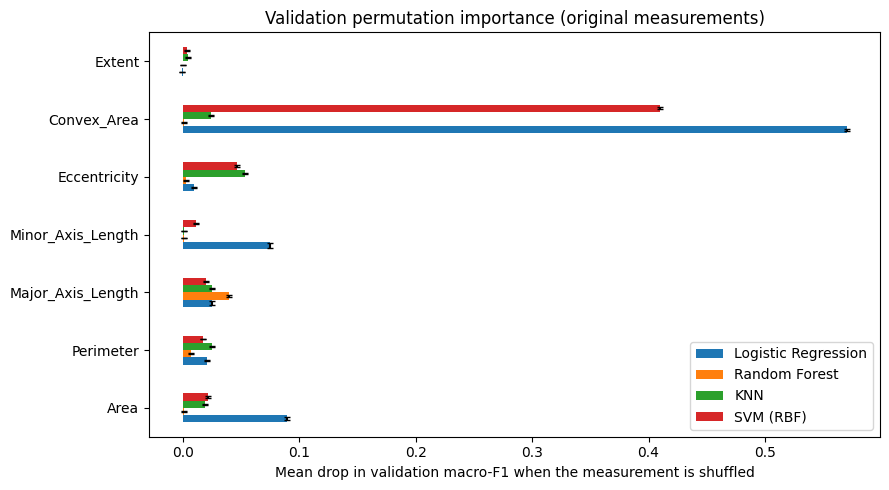

In [27]:
perm_mean = pd.DataFrame({a: v[0].mean() for a, v in orig_perm_folds.items()})
perm_sd   = pd.DataFrame({a: v[0].std()  for a, v in orig_perm_folds.items()})

display(perm_mean.round(4))     # mean macro-F1 drop on validation folds
display(perm_sd.round(4))       # variability across folds

perm_mean.plot(kind='barh', yerr=perm_sd, capsize=2, figsize=(9, 5))
plt.xlabel("Mean drop in validation macro-F1 when the measurement is shuffled")
plt.title("Validation permutation importance (original measurements)")
plt.tight_layout(); plt.show()

In [28]:
!pip install -q shap

,Mean |SHAP|
Major_Axis_Length,0.1678
Perimeter,0.1203
Convex_Area,0.0592
Area,0.0557
Eccentricity,0.0442
Minor_Axis_Length,0.0053
Extent,0.0026


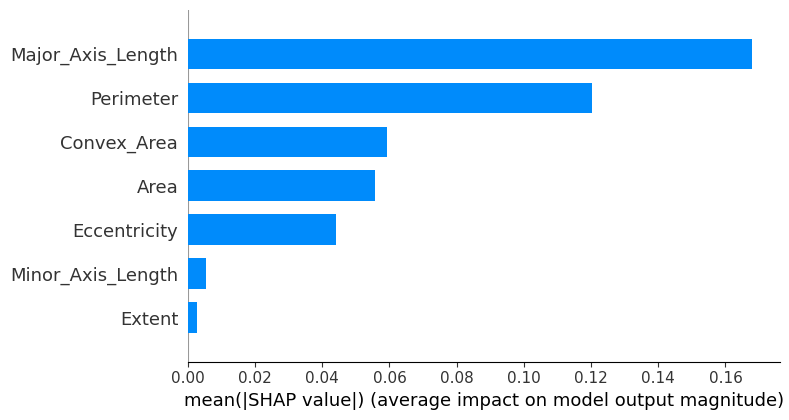

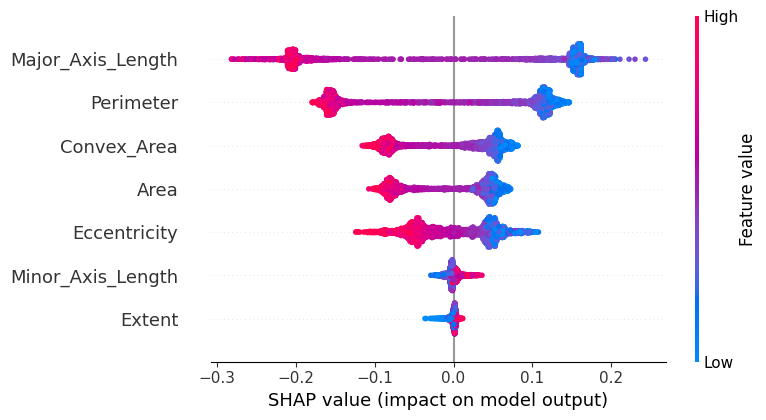

In [29]:
import shap

rf_template = full_search['Random Forest'].best_estimator_      # Random Forest uses the raw measurements
shap_oof  = np.zeros((len(X_orig_train), len(original_features)))
base_oof  = np.zeros(len(X_orig_train))
proba_oof = np.zeros(len(X_orig_train))

for tr, va in cv.split(X_orig_train, y_train):                  # SHAP on held-out validation rows only
    pipe = clone(rf_template).fit(X_orig_train.iloc[tr], y_train[tr])
    explainer = shap.TreeExplainer(pipe.named_steps['model'])
    Xva = X_orig_train.iloc[va]
    sv = explainer.shap_values(Xva)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)   # Osmancik class
    ev = explainer.expected_value
    shap_oof[va]  = sv
    base_oof[va]  = ev[1] if np.ndim(ev) else ev
    proba_oof[va] = pipe.predict_proba(Xva)[:, 1]

shap_global = pd.Series(np.abs(shap_oof).mean(axis=0), index=original_features).sort_values(ascending=False)
display(shap_global.round(4).to_frame('Mean |SHAP|'))

shap.summary_plot(shap_oof, X_orig_train, plot_type='bar')
shap.summary_plot(shap_oof, X_orig_train)

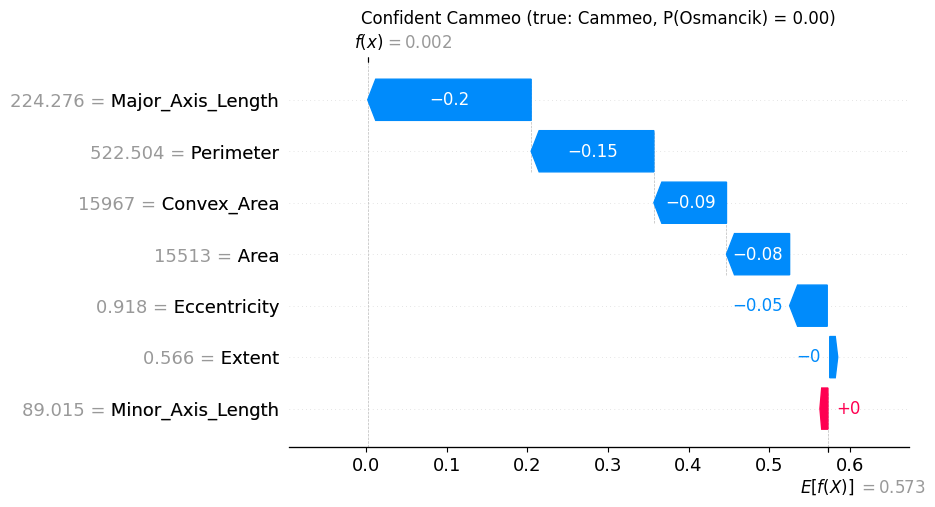

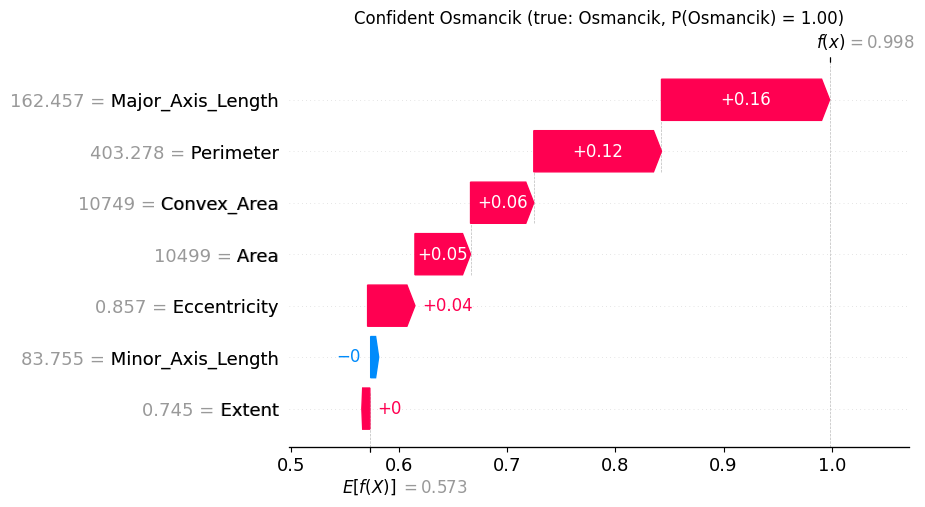

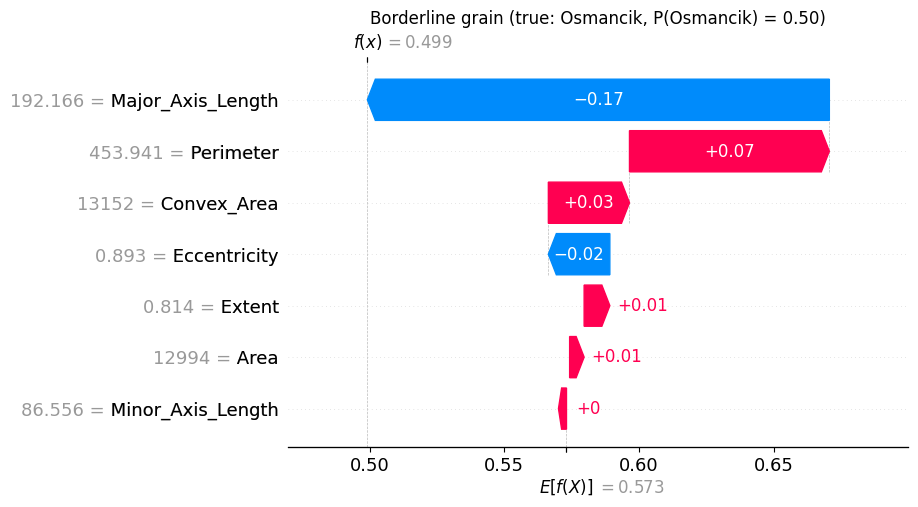

In [30]:
# Selected example explanations (out-of-fold)
def pick(mask, key):
    pos = np.where(mask)[0]
    return pos[np.argmin(key[pos])]

correct = ((proba_oof >= 0.5).astype(int) == y_train)
examples = {
    'Confident Cammeo':    pick(correct & (y_train == 0),  proba_oof),
    'Confident Osmancik':  pick(correct & (y_train == 1), -proba_oof),
    'Borderline grain':    pick(np.ones(len(y_train), dtype=bool), np.abs(proba_oof - 0.5)),
}

for title, i in examples.items():
    exp = shap.Explanation(values=shap_oof[i], base_values=base_oof[i],
                           data=X_orig_train.iloc[i].values, feature_names=original_features)
    shap.plots.waterfall(exp, show=False)
    plt.title(f"{title} (true: {le.classes_[y_train[i]]}, P(Osmancik) = {proba_oof[i]:.2f})")
    plt.show()

These importances describe each measurement's **contribution to the model's predictions**, not a
causal effect on rice variety. Logistic Regression coefficients are in RobustScaler units and can be
unstable when inputs are correlated. Importance used for selection comes from held-out validation folds.

## Step 10 – Ranking stability across folds

In [31]:
def stability_table(algo):
    imp, ranks = orig_perm_folds[algo]
    return pd.DataFrame({
        'Mean importance': imp.mean(),
        'SD across folds': imp.std(),
        'Mean rank': ranks.mean(),
        'Rank range': ranks.min().map('{:g}'.format) + '–' + ranks.max().map('{:g}'.format),
    }).sort_values('Mean rank')

for algo in ALGOS:
    print(f"\n{algo}")
    display(stability_table(algo).round(4))


Logistic Regression


,Mean importance,SD across folds,Mean rank,Rank range
Convex_Area,0.5703,0.0181,1.0000,1–1
Area,0.0895,0.0205,2.4000,2–3
Minor_Axis_Length,0.0748,0.0408,3.0000,2–4
Perimeter,0.0206,0.0102,4.6000,4–5
Major_Axis_Length,0.0247,0.0340,4.8000,3–6
Eccentricity,0.0100,0.0126,5.4000,3–7
Extent,-0.0004,0.0026,6.8000,6–7



Random Forest


,Mean importance,SD across folds,Mean rank,Rank range
Major_Axis_Length,0.0400,0.0129,1.0000,1–1
Perimeter,0.0066,0.0065,2.8000,2–6
Eccentricity,0.0030,0.0032,3.0000,2–4
Convex_Area,0.0014,0.0039,4.8000,3–7
Area,0.0009,0.0026,5.1000,4–6
Minor_Axis_Length,0.0007,0.0015,5.2000,3–7
Extent,-0.0000,0.0012,6.1000,4–7



KNN


,Mean importance,SD across folds,Mean rank,Rank range
Eccentricity,0.0533,0.0080,1.0000,1–1
Major_Axis_Length,0.0254,0.0072,2.8000,2–4
Perimeter,0.0246,0.0063,3.0000,3–3
Convex_Area,0.0244,0.0067,3.2000,2–4
Area,0.0190,0.0065,5.0000,5–5
Extent,0.0043,0.0020,6.0000,6–6
Minor_Axis_Length,0.0013,0.0030,7.0000,7–7



SVM (RBF)


,Mean importance,SD across folds,Mean rank,Rank range
Convex_Area,0.4095,0.0233,1.0000,1–1
Eccentricity,0.0469,0.0116,2.0000,2–2
Area,0.0212,0.0102,4.0000,3–6
Major_Axis_Length,0.0195,0.0071,4.0000,3–5
Perimeter,0.0177,0.0044,4.6000,3–6
Minor_Axis_Length,0.0113,0.0070,5.6000,4–7
Extent,0.0034,0.0028,6.8000,6–7


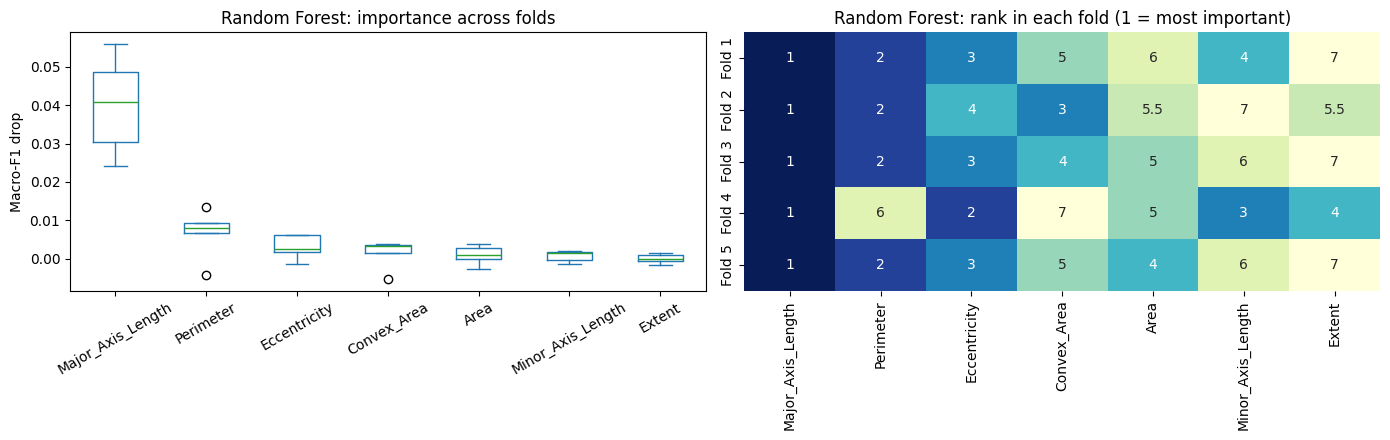

In [32]:
imp_sel, rank_sel = orig_perm_folds[SELECTED_ALGO]
order = rank_sel.mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
imp_sel[order].plot(kind='box', ax=axes[0], rot=30)
axes[0].set_title(f"{SELECTED_ALGO}: importance across folds"); axes[0].set_ylabel("Macro-F1 drop")
sns.heatmap(rank_sel[order], annot=True, fmt='g', cmap='YlGnBu_r', cbar=False, ax=axes[1])
axes[1].set_title(f"{SELECTED_ALGO}: rank in each fold (1 = most important)")
plt.tight_layout(); plt.show()

## Step 11 – Reconcile the methods and test correlated groups

In [33]:
PERM_ALGO = SELECTED_ALGO       # whose validation permutation ranking to use in the comparison

rank_table = pd.DataFrame({
    'Coefficient rank': coef.abs().rank(ascending=False),
    'RF rank':          rf_imp.rank(ascending=False),
    'Permutation rank': orig_perm_folds[PERM_ALGO][0].mean().rank(ascending=False),
    'SHAP rank':        shap_global.rank(ascending=False),
})
rank_table['Median rank'] = rank_table.median(axis=1)
rank_table['Rank spread'] = rank_table.iloc[:, :4].max(axis=1) - rank_table.iloc[:, :4].min(axis=1)
rank_table['Agreement'] = np.where(rank_table['Rank spread'] <= 1, 'High',
                           np.where(rank_table['Rank spread'] <= 3, 'Moderate', 'Low'))
rank_table.sort_values('Median rank')      # write the Interpretation for each row in a markdown cell below

,Coefficient rank,RF rank,Permutation rank,SHAP rank,Median rank,Rank spread,Agreement
Major_Axis_Length,5.0000,1.0000,1.0000,1.0000,1.0000,4.0000,Low
Perimeter,3.0000,2.0000,2.0000,2.0000,2.0000,1.0000,High
Area,2.0000,3.0000,5.0000,4.0000,3.5000,3.0000,Moderate
Convex_Area,1.0000,4.0000,4.0000,3.0000,3.5000,3.0000,Moderate
Eccentricity,6.0000,5.0000,3.0000,5.0000,5.0000,3.0000,Moderate
Minor_Axis_Length,4.0000,6.0000,6.0000,6.0000,6.0000,2.0000,Moderate
Extent,7.0000,7.0000,7.0000,7.0000,7.0000,0.0000,High


**Reconciliation of the methods.** (One line per measurement: explain where the four rankings agree or
disagree. Compare ranks only; do not average raw importance values that have different units.)

| Measurement | Interpretation |
|---|---|
| ... | ... |

In [34]:
def paired_cv(algo, cols):
    """CV macro-F1 per fold with the already-tuned hyperparameters of `algo` (fixed-hyperparameter comparison)."""
    res = cross_validate(clone(full_search[algo].best_estimator_), X_orig_train[cols], y_train,
                         cv=cv, scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy'})
    return res['test_f1_macro'], res['test_accuracy']

base_f1 = {a: paired_cv(a, original_features)[0] for a in ALGOS}

loo = {}
for feat in original_features:
    cols = [f for f in original_features if f != feat]
    loo[f'Drop {feat}'] = {a: (paired_cv(a, cols)[0] - base_f1[a]).mean() * 100 for a in ALGOS}

loo_df = pd.DataFrame(loo).T
display(loo_df.round(2))        # change in CV macro-F1, percentage points, vs all seven measurements

,Logistic Regression,Random Forest,KNN,SVM (RBF)
Drop Area,0.0000,-0.0700,-0.1400,-0.0300
Drop Perimeter,-0.1400,0.0700,-0.3300,-0.0300
Drop Major_Axis_Length,-0.0700,-0.1700,-0.1300,-0.2000
Drop Minor_Axis_Length,-0.1700,0.0400,-0.1000,-0.1000
Drop Eccentricity,0.0300,-0.1400,-0.3400,-0.2700
Drop Convex_Area,-0.3300,-0.1300,0.0700,-0.4400
Drop Extent,0.0300,-0.1000,-0.1100,-0.2400


In [35]:
rep_rows = []
for gname, members in corr_groups.items():
    if len(members) < 2:
        continue
    others = [f for f in original_features if f not in members]
    for m in members:
        cols = others + [m]
        row = {'Group': gname, 'Kept from group': m, 'Measurements used': len(cols)}
        for a in ALGOS:
            row[a] = (paired_cv(a, cols)[0] - base_f1[a]).mean() * 100
        rep_rows.append(row)

rep_df = pd.DataFrame(rep_rows)
rep_df.round(2)         # Δ CV macro-F1 (pp): the rest of the group is removed, one representative is kept

,Group,Kept from group,Measurements used,Logistic Regression,Random Forest,KNN,SVM (RBF)
0,Group 1,Area,4,-0.4200,-0.3000,-0.2700,-0.3700
1,Group 1,Perimeter,4,-0.2600,-0.2300,-0.2100,-0.5500
2,Group 1,Major_Axis_Length,4,-0.3200,0.0700,-0.1700,-0.4700
3,Group 1,Convex_Area,4,-0.1000,-0.0400,-0.2400,-0.0400


In [36]:
def grouped_permutation(algo, groups, n_repeats=10, seed=42):
    """Shuffle all measurements of a group together on the validation rows of each fold."""
    from sklearn.metrics import f1_score
    rng = np.random.RandomState(seed)
    rows = []
    for k, (tr, va) in enumerate(cv.split(X_orig_train, y_train), 1):
        pipe = clone(full_search[algo].best_estimator_).fit(X_orig_train.iloc[tr], y_train[tr])
        Xva, yva = X_orig_train.iloc[va], y_train[va]
        base = f1_score(yva, pipe.predict(Xva), average='macro')
        row = {}
        for gname, cols in groups.items():
            drops = []
            for _ in range(n_repeats):
                Xp = Xva.copy()
                Xp[cols] = Xva[cols].values[rng.permutation(len(Xva))]      # same row order for the whole group
                drops.append(base - f1_score(yva, pipe.predict(Xp), average='macro'))
            row[gname] = np.mean(drops)
        rows.append(pd.Series(row, name=f'Fold {k}'))
    return pd.DataFrame(rows)

group_cols = {' + '.join(m): m for m in corr_groups.values()}
joint = grouped_permutation(SELECTED_ALGO, group_cols)

indiv = orig_perm_folds[SELECTED_ALGO][0].mean()
summary = pd.DataFrame({
    'Joint shuffle: mean drop': joint.mean(),
    'Joint shuffle: SD': joint.std(),
    'Sum of members\' individual drops': {g: indiv[c].sum() for g, c in group_cols.items()},
})
summary.round(4)

,Joint shuffle: mean drop,Joint shuffle: SD,Sum of members' individual drops
Area + Perimeter + Major_Axis_Length + Convex_Area,0.4188,0.0132,0.0489
Minor_Axis_Length,0.0011,0.0016,0.0007
Eccentricity,0.0030,0.0043,0.0030
Extent,-0.0001,0.0013,-0.0000


**Correlated groups.** If removing a measurement barely changes macro-F1 while its group's joint shuffle
causes a large drop, the measurement has *low independent importance*, but the group's information is
needed (a correlated substitute carries it). Findings: __.

## Step 12 – Shortlist of reduced original-feature subsets

In [37]:
FULL_NAME = 'All 7 original (reference)'
cand = {FULL_NAME: (original_features, 'Reference set')}
cand['Existing 3-feature candidate'] = (['Minor_Axis_Length', 'Eccentricity', 'Extent'],
    'Existing VIF-derived candidate (exploratory fixed candidate; low VIF alone does not make it best)')

consensus = rank_table[['Coefficient rank', 'RF rank', 'Permutation rank', 'SHAP rank']].median(axis=1).sort_values()
cand['Top-3 by consensus rank'] = (list(consensus.index[:3]), 'Best median rank across the four importance methods')
cand['Top-4 by consensus rank'] = (list(consensus.index[:4]), 'Adds the next-ranked measurement')
cand['One representative per correlated group'] = (
    [min(m, key=lambda f: consensus[f]) for m in corr_groups.values()],
    'Best-ranked measurement of each correlated group; tests whether one measurement can stand in for its group')

# add your own evidence-based candidates here, e.g.
# cand['My candidate'] = (['Area', 'Eccentricity', 'Extent'], 'Why: ...')

shortlist, shortlist_reason, seen = {}, {}, {}
for name, (cols, why) in cand.items():
    key = frozenset(cols)
    if key in seen:
        print(f"'{name}' has the same measurements as '{seen[key]}' - skipped")
        continue
    seen[key] = name
    shortlist[name] = [f for f in original_features if f in cols]      # keep the original column order
    shortlist_reason[name] = why

pd.DataFrame({'Measurements': {n: ', '.join(c) for n, c in shortlist.items()},
              'Count': {n: len(c) for n, c in shortlist.items()},
              'Reason': shortlist_reason})

,Measurements,Count,Reason
All 7 original (reference),"Area, Perimeter, Major_Axis_Length, Minor_Axis...",7,Reference set
Existing 3-feature candidate,"Minor_Axis_Length, Eccentricity, Extent",3,Existing VIF-derived candidate (exploratory fi...
Top-3 by consensus rank,"Area, Perimeter, Major_Axis_Length",3,Best median rank across the four importance me...
Top-4 by consensus rank,"Area, Perimeter, Major_Axis_Length, Convex_Area",4,Adds the next-ranked measurement
One representative per correlated group,"Major_Axis_Length, Minor_Axis_Length, Eccentri...",4,Best-ranked measurement of each correlated gro...


## Step 13 – Retune the shortlisted subsets and compare with the full model of the same algorithm

In [38]:
subset_search = {}
for sname, cols in shortlist.items():
    for algo in ALGOS:
        if sname == FULL_NAME:
            subset_search[(sname, algo)] = full_search[algo]            # already tuned in Step 7
        else:
            subset_search[(sname, algo)] = make_search(algo).fit(X_orig_train[cols], y_train)
    print("done:", sname)

done: All 7 original (reference)
done: Existing 3-feature candidate
done: Top-3 by consensus rank
done: Top-4 by consensus rank
done: One representative per correlated group


In [39]:
def fold_scores(gs, metric):
    i = gs.best_index_
    return np.array([gs.cv_results_[f'split{k}_test_{metric}'][i] for k in range(cv.get_n_splits())])

res_rows = []
for (sname, algo), gs in subset_search.items():
    ref = full_search[algo]
    d_f1  = fold_scores(gs, 'f1_macro') - fold_scores(ref, 'f1_macro')           # paired by fold
    s = summarize_search(gs)
    row = {
        'Subset': sname, 'Algorithm': algo, 'Measurements': len(shortlist[sname]),
        'CV macro-F1': s['CV macro-F1'], 'CV SD': s['CV macro-F1 SD'], 'CV accuracy': s['CV accuracy'],
        'Δ macro-F1 (pp)': d_f1.mean() * 100, 'Δ macro-F1 SD (pp, paired folds)': d_f1.std() * 100,
        'Δ accuracy (pp)': (fold_scores(gs, 'accuracy') - fold_scores(ref, 'accuracy')).mean() * 100,
        'Δ recall Cammeo (pp)':   (fold_scores(gs, 'recall_cammeo')   - fold_scores(ref, 'recall_cammeo')).mean() * 100,
        'Δ recall Osmancik (pp)': (fold_scores(gs, 'recall_osmancik') - fold_scores(ref, 'recall_osmancik')).mean() * 100,
        'Best parameters': s['Best parameters'],
    }
    row['Within macro-F1 tolerance'] = row['Δ macro-F1 (pp)'] >= -TOLERANCE_PP
    row['Recall OK'] = min(row['Δ recall Cammeo (pp)'], row['Δ recall Osmancik (pp)']) >= -RECALL_DROP_PP
    res_rows.append(row)

subset_results = pd.DataFrame(res_rows)
display(subset_results.sort_values(['Algorithm', 'Measurements']).round(4))
display(subset_results.pivot(index='Subset', columns='Algorithm', values='Δ macro-F1 (pp)').round(2))

,Subset,Algorithm,Measurements,CV macro-F1,CV SD,CV accuracy,Δ macro-F1 (pp),"Δ macro-F1 SD (pp, paired folds)",Δ accuracy (pp),Δ recall Cammeo (pp),Δ recall Osmancik (pp),Best parameters,Within macro-F1 tolerance,Recall OK
6,Existing 3-feature candidate,KNN,3,0.9279,0.0087,0.9295,-0.1450,0.4420,-0.1311,-0.6908,0.2870,{'n_neighbors': 13},True,True
10,Top-3 by consensus rank,KNN,3,0.9283,0.0101,0.9298,-0.0999,0.1747,-0.0984,-0.0766,-0.1144,{'n_neighbors': 31},True,True
14,Top-4 by consensus rank,KNN,4,0.9293,0.0101,0.9308,-0.0071,0.1046,-0.0000,-0.3837,0.2872,{'n_neighbors': 17},True,True
18,One representative per correlated group,KNN,4,0.9286,0.0080,0.9301,-0.0717,0.2232,-0.0656,-0.3068,0.1146,{'n_neighbors': 23},True,True
2,All 7 original (reference),KNN,7,0.9293,0.0101,0.9308,0.0000,0.0000,0.0000,0.0000,0.0000,{'n_neighbors': 27},True,True
4,Existing 3-feature candidate,Logistic Regression,3,0.9307,0.0088,0.9321,-0.2230,0.4339,-0.2295,0.3840,-0.6880,{'C': 0.1},True,True
8,Top-3 by consensus rank,Logistic Regression,3,0.9313,0.0095,0.9327,-0.1697,0.3198,-0.1640,-0.3068,-0.0573,{'C': 1},True,True
12,Top-4 by consensus rank,Logistic Regression,4,0.9336,0.0086,0.9350,0.0673,0.2905,0.0656,0.0769,0.0571,{'C': 100},True,True
16,One representative per correlated group,Logistic Regression,4,0.9303,0.0087,0.9318,-0.2616,0.4717,-0.2623,0.0772,-0.5159,{'C': 0.1},True,True
0,All 7 original (reference),Logistic Regression,7,0.9330,0.0084,0.9344,0.0000,0.0000,0.0000,0.0000,0.0000,{'C': 100},True,True


Algorithm,KNN,Logistic Regression,Random Forest,SVM (RBF)
Subset,,,,
All 7 original (reference),0.0000,0.0000,0.0000,0.0000
Existing 3-feature candidate,-0.1400,-0.2200,-0.8700,-0.1200
One representative per correlated group,-0.0700,-0.2600,0.2000,-0.1900
Top-3 by consensus rank,-0.1000,-0.1700,0.1000,-0.1100
Top-4 by consensus rank,-0.0100,0.0700,-0.1300,0.0200


## Frozen choice and final evaluation
The algorithm and subset below were selected using **training-data cross-validation only** (Steps 8 and 13).
Both pipelines are fitted on all training rows and evaluated once on the same test rows. Because test
results were inspected in earlier experiments, this is a limitation-aware check rather than a clean
confirmation. A small observed difference alone does not establish equivalence; it is judged by the
confidence interval against the documented tolerance.

In [40]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay, classification_report)

# Set these from TRAINING-CV evidence only (Steps 8 and 13), then do not change them after looking at the test rows.
FINAL_ALGO   = 'Random Forest'
FINAL_SUBSET = list(shortlist)[-1]          # must be a key of `shortlist`; replace with your chosen subset name
print("Final subset:", FINAL_SUBSET, "->", shortlist[FINAL_SUBSET])

final_cols   = shortlist[FINAL_SUBSET]
full_pipe    = full_search[FINAL_ALGO].best_estimator_                          # fitted on all training rows
reduced_pipe = subset_search[(FINAL_SUBSET, FINAL_ALGO)].best_estimator_        # fitted on all training rows

def get_score(pipe, X):
    return pipe.predict_proba(X)[:, 1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(X)

pred_full = full_pipe.predict(X_orig_test[original_features]);  score_full = get_score(full_pipe, X_orig_test[original_features])
pred_red  = reduced_pipe.predict(X_orig_test[final_cols]);      score_red  = get_score(reduced_pipe, X_orig_test[final_cols])

def test_metrics(yp, ys):
    return {'Accuracy': accuracy_score(y_test, yp), 'Balanced accuracy': balanced_accuracy_score(y_test, yp),
            'Macro-F1': f1_score(y_test, yp, average='macro'),
            'Recall Cammeo': recall_score(y_test, yp, pos_label=0), 'Recall Osmancik': recall_score(y_test, yp, pos_label=1),
            'ROC-AUC': roc_auc_score(y_test, ys)}

final_table = pd.DataFrame({f'Full (7 measurements)': test_metrics(pred_full, score_full),
                            f'Reduced ({len(final_cols)} measurements)': test_metrics(pred_red, score_red)})
final_table.round(4)

Final subset: One representative per correlated group -> ['Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']


,Full (7 measurements),Reduced (4 measurements)
Accuracy,0.9186,0.9147
Balanced accuracy,0.9138,0.9108
Macro-F1,0.9163,0.9125
Recall Cammeo,0.8804,0.8834
Recall Osmancik,0.9472,0.9381
ROC-AUC,0.9742,0.9734


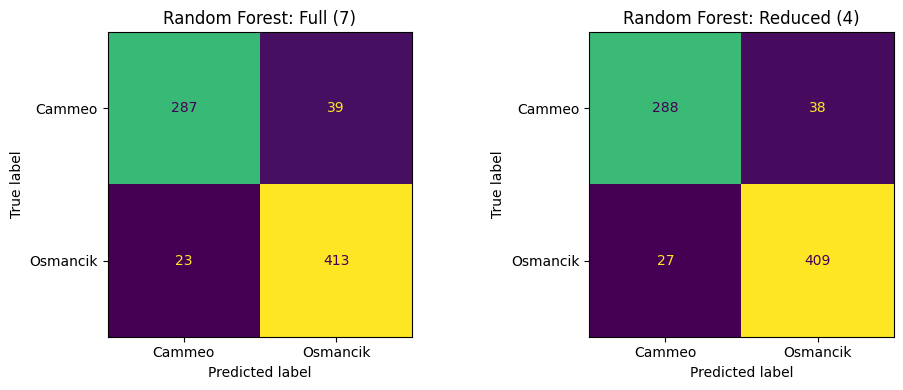

FULL
               precision    recall  f1-score   support

      Cammeo     0.9258    0.8804    0.9025       326
    Osmancik     0.9137    0.9472    0.9302       436

    accuracy                         0.9186       762
   macro avg     0.9198    0.9138    0.9163       762
weighted avg     0.9189    0.9186    0.9183       762

REDUCED
               precision    recall  f1-score   support

      Cammeo     0.9143    0.8834    0.8986       326
    Osmancik     0.9150    0.9381    0.9264       436

    accuracy                         0.9147       762
   macro avg     0.9146    0.9108    0.9125       762
weighted avg     0.9147    0.9147    0.9145       762



In [41]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, yp) in zip(axes, [('Full (7)', pred_full), (f'Reduced ({len(final_cols)})', pred_red)]):
    ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=le.classes_, ax=ax, colorbar=False)
    ax.set_title(f"{FINAL_ALGO}: {title}")
plt.tight_layout(); plt.show()

print("FULL\n", classification_report(y_test, pred_full, target_names=le.classes_, digits=4))
print("REDUCED\n", classification_report(y_test, pred_red, target_names=le.classes_, digits=4))

In [42]:
metric_fns = {
    'Macro-F1':        lambda yt, yp: f1_score(yt, yp, average='macro'),
    'Accuracy':        accuracy_score,
    'Recall Cammeo':   lambda yt, yp: recall_score(yt, yp, pos_label=0),
    'Recall Osmancik': lambda yt, yp: recall_score(yt, yp, pos_label=1),
}

B = 2000
rng = np.random.RandomState(42)
n = len(y_test)
boot = {m: [] for m in metric_fns}
for _ in range(B):
    idx = rng.randint(0, n, n)                      # the SAME resampled test rows for both pipelines (paired)
    for m, fn in metric_fns.items():
        boot[m].append(fn(y_test[idx], pred_red[idx]) - fn(y_test[idx], pred_full[idx]))

rows = []
for m, fn in metric_fns.items():
    lo, hi = np.percentile(boot[m], [2.5, 97.5])
    rows.append({'Metric': m, 'Observed Δ (pp)': (fn(y_test, pred_red) - fn(y_test, pred_full)) * 100,
                 '95% CI low (pp)': lo * 100, '95% CI high (pp)': hi * 100})
paired = pd.DataFrame(rows).set_index('Metric')
display(paired.round(2))

lo_f1 = paired.loc['Macro-F1', '95% CI low (pp)']
print(f"Tolerance: -{TOLERANCE_PP} pp macro-F1. CI lower bound = {lo_f1:.2f} pp -> "
      + ("lower bound is inside the tolerance: non-inferiority is supported on this test set (with the limitations noted)."
         if lo_f1 >= -TOLERANCE_PP else
         "lower bound is below the tolerance: equivalence within the tolerance is NOT established."))

,Observed Δ (pp),95% CI low (pp),95% CI high (pp)
Metric,,,
Macro-F1,-0.3900,-1.0600,0.2900
Accuracy,-0.3900,-1.0500,0.2600
Recall Cammeo,0.3100,-0.6300,1.3200
Recall Osmancik,-0.9200,-1.8800,-0.2200


Tolerance: -1.0 pp macro-F1. CI lower bound = -1.06 pp -> lower bound is below the tolerance: equivalence within the tolerance is NOT established.


# Comparison experiment: engineered features
The main analysis above works with the seven original measurements. The sections below keep the
engineered-feature experiment as a **separate comparison**. It uses the same train/test rows.

##Feature Engineering

In [43]:
df_fe = df.copy()

df_fe['Aspect_Ratio'] = df_fe['Major_Axis_Length'] / df_fe['Minor_Axis_Length']
df_fe['Circularity']  = (4 * np.pi * df_fe['Area']) / (df_fe['Perimeter'] ** 2)
df_fe['Solidity']     = df_fe['Area'] / df_fe['Convex_Area']

new_feats = ['Aspect_Ratio', 'Circularity', 'Solidity']

###New Features

  - Aspect_Ratio = Major_Axis_Length / Minor_Axis_Length
  - Circularity = (4π × Area) / Perimeter²
  - Solidity = Area / Convex_Area

In [44]:
print("NaN / inf check:")
print(df_fe[new_feats].isnull().sum())
print("Inf values:", np.isinf(df_fe[new_feats]).sum().sum())

df_fe[new_feats].describe().T

NaN / inf check:
Aspect_Ratio    0
Circularity     0
Solidity        0
dtype: int64
Inf values: 0


,count,mean,std,min,25%,50%,75%,max
Aspect_Ratio,3810.0000,2.1908,0.1895,1.5893,2.0459,2.1843,2.3229,3.1422
Circularity,3810.0000,0.7698,0.0330,0.6203,0.7461,0.7698,0.7940,0.9027
Solidity,3810.0000,0.9781,0.0061,0.9263,0.9743,0.9788,0.9828,0.9903


In [45]:
drop_cols = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
             'Eccentricity', 'Convex_Area']

df_fe = df_fe.drop(columns=drop_cols)

final_features = [c for c in df_fe.columns if c != target_col]
print("Final features:", final_features)
df_fe.head()

Final features: ['Area', 'Extent', 'Aspect_Ratio', 'Circularity', 'Solidity']


,Area,Extent,Class,Aspect_Ratio,Circularity,Solidity
0,15231.0000,0.5729,Cammeo,2.7000,0.6929,0.9753
1,14656.0000,0.6154,Cammeo,2.2459,0.7537,0.9724
2,14634.0000,0.6933,Cammeo,2.4395,0.7323,0.9786
3,13176.0000,0.6407,Cammeo,2.2109,0.7882,0.9856
4,14688.0000,0.6460,Cammeo,2.3708,0.7176,0.9624


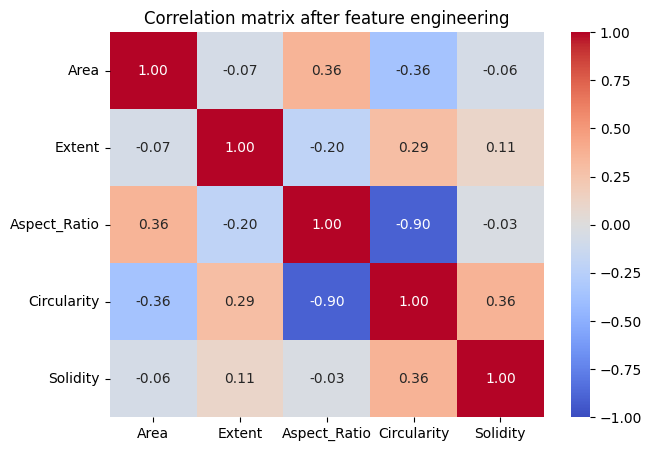

In [46]:
corr_new = df_fe.loc[train_idx, final_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_new, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix after feature engineering')
plt.show()

Final observation: Still correlated

In [47]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(df_fe.loc[train_idx, final_features])

vif = pd.DataFrame({
    'Feature': final_features,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1)
            for i in range(len(final_features))]
})
vif

,Feature,VIF
0,Area,1.1602
1,Extent,1.1346
2,Aspect_Ratio,11.2079
3,Circularity,13.4912
4,Solidity,2.4411


###Trying different features

In [48]:
df_v2 = df.copy()

df_v2['Perimeter_Area_Ratio'] = df_v2['Perimeter'] / df_v2['Area']

df_v2['Area_Axis_Product_Ratio'] = df_v2['Area'] / (df_v2['Major_Axis_Length'] * df_v2['Minor_Axis_Length'])

* Area_Axis_Product_Ratio = Area / (Major_Axis_Length × Minor_Axis_Length)
* Perimeter_Area_Ratio = Perimeter / Area

In [49]:
keep_cols = ['Eccentricity', 'Extent', 'Area_Axis_Product_Ratio', 'Perimeter_Area_Ratio']

df_v2 = df_v2[keep_cols + [target_col]]
final_features_v2 = keep_cols

print("Final features:", final_features_v2)
df_v2.head()

Final features: ['Eccentricity', 'Extent', 'Area_Axis_Product_Ratio', 'Perimeter_Area_Ratio']


,Eccentricity,Extent,Area_Axis_Product_Ratio,Perimeter_Area_Ratio,Class
0,0.9289,0.5729,0.7791,0.0345,Cammeo
1,0.8954,0.6154,0.7755,0.0337,Cammeo
2,0.9121,0.6933,0.7787,0.0342,Cammeo
3,0.8919,0.6407,0.7793,0.0348,Cammeo
4,0.9067,0.6460,0.7767,0.0345,Cammeo


In [50]:
print("Missing values:\n", df_v2[final_features_v2].isnull().sum())
print("Inf values:", np.isinf(df_v2[final_features_v2]).sum().sum())

df_v2[final_features_v2].describe().T

Missing values:
 Eccentricity               0
Extent                     0
Area_Axis_Product_Ratio    0
Perimeter_Area_Ratio       0
dtype: int64
Inf values: 0


,count,mean,std,min,25%,50%,75%,max
Eccentricity,3810.0000,0.8869,0.0208,0.7772,0.8724,0.8891,0.9026,0.9480
Extent,3810.0000,0.6619,0.0772,0.4974,0.5989,0.6454,0.7266,0.8610
Area_Axis_Product_Ratio,3810.0000,0.7753,0.0040,0.7580,0.7729,0.7756,0.7780,0.7839
Perimeter_Area_Ratio,3810.0000,0.0362,0.0023,0.0286,0.0345,0.0361,0.0376,0.0489


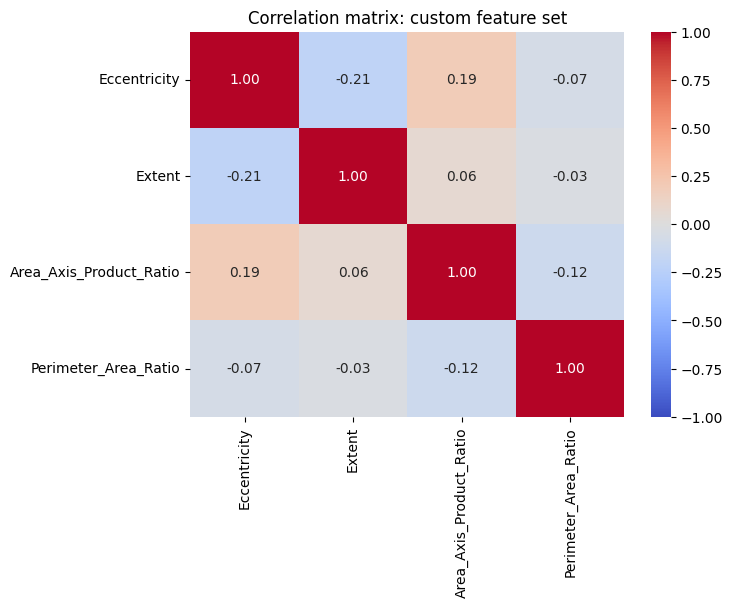

In [51]:
corr_v2 = df_v2.loc[train_idx, final_features_v2].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_v2, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix: custom feature set')
plt.show()

Observation: Split ready

In [52]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif_v2 = add_constant(df_v2.loc[train_idx, final_features_v2])

vif_v2 = pd.DataFrame({
    'Feature': final_features_v2,
    'VIF': [variance_inflation_factor(X_vif_v2.values, i + 1)
            for i in range(len(final_features_v2))]
})
vif_v2

,Feature,VIF
0,Eccentricity,1.0944
1,Extent,1.0582
2,Area_Axis_Product_Ratio,1.0618
3,Perimeter_Area_Ratio,1.0186


##Encoding

In [53]:
X = df_v2[final_features_v2].copy()
y_raw = df_v2[target_col].copy()

print("X shape:", X.shape)
print("Target classes:", y_raw.unique())

X shape: (3810, 4)
Target classes: ['Cammeo' 'Osmancik']


In [54]:
#Encoding the target
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y_raw)

print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("y shape:", y.shape)

Class mapping: {'Cammeo': np.int64(0), 'Osmancik': np.int64(1)}
y shape: (3810,)


###Cammeo: 0, Osmancik: 1

##80%-20% Train Test data split

In [55]:
# Cell 42 replacement (engineered-feature block): reuse the early split instead of splitting again
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Proof that the rows are exactly the ones used before
_chk = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
assert _chk[0].index.equals(X_train.index) and _chk[1].index.equals(X_test.index), "split changed!"
print("Split identical to the original split: OK")


Train: (3048, 4) | Test: (762, 4)
Split identical to the original split: OK


In [56]:
split_summary = pd.DataFrame({
    'Overall': np.bincount(y) / len(y),
    'Train':   np.bincount(y_train) / len(y_train),
    'Test':    np.bincount(y_test) / len(y_test)
}, index=le.classes_)

split_summary

,Overall,Train,Test
Cammeo,0.4278,0.4278,0.4278
Osmancik,0.5722,0.5722,0.5722


In [57]:
print("Train class counts:", dict(zip(le.classes_, np.bincount(y_train))))
print("Test class counts :", dict(zip(le.classes_, np.bincount(y_test))))

Train class counts: {'Cammeo': np.int64(1304), 'Osmancik': np.int64(1744)}
Test class counts : {'Cammeo': np.int64(326), 'Osmancik': np.int64(436)}


##Data Scaling

In [58]:
skew_kurt = pd.DataFrame({
    'Skewness': X_train.skew(),
    'Kurtosis': X_train.kurt()
})

def skew_level(s):
    s = abs(s)
    if s < 0.5:
        return 'Symmetric'
    elif s < 1:
        return 'Moderate'
    return 'High'

skew_kurt['Skew_Level'] = skew_kurt['Skewness'].apply(skew_level)
skew_kurt

,Skewness,Kurtosis,Skew_Level
Eccentricity,-0.4552,0.0897,Symmetric
Extent,0.3264,-1.0573,Symmetric
Area_Axis_Product_Ratio,-0.5481,0.3529,Moderate
Perimeter_Area_Ratio,0.3852,0.6008,Symmetric


In [59]:
def iqr_outlier_summary(data):
    rows = []
    for col in data.columns:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_low  = (data[col] < lower).sum()
        n_high = (data[col] > upper).sum()
        rows.append({
            'Feature': col,
            'Lower_Bound': lower,
            'Upper_Bound': upper,
            'Low_Outliers': n_low,
            'High_Outliers': n_high,
            'Total_Outliers': n_low + n_high,
            'Outlier_%': 100 * (n_low + n_high) / len(data)
        })
    return pd.DataFrame(rows).set_index('Feature')

outlier_summary = iqr_outlier_summary(X_train)
outlier_summary

,Lower_Bound,Upper_Bound,Low_Outliers,High_Outliers,Total_Outliers,Outlier_%
Feature,,,,,,
Eccentricity,0.8255,0.9487,14,0,14,0.4593
Extent,0.4051,0.9219,0,0,0,0.0000
Area_Axis_Product_Ratio,0.7650,0.7859,40,0,40,1.3123
Perimeter_Area_Ratio,0.0299,0.0422,3,34,37,1.2139


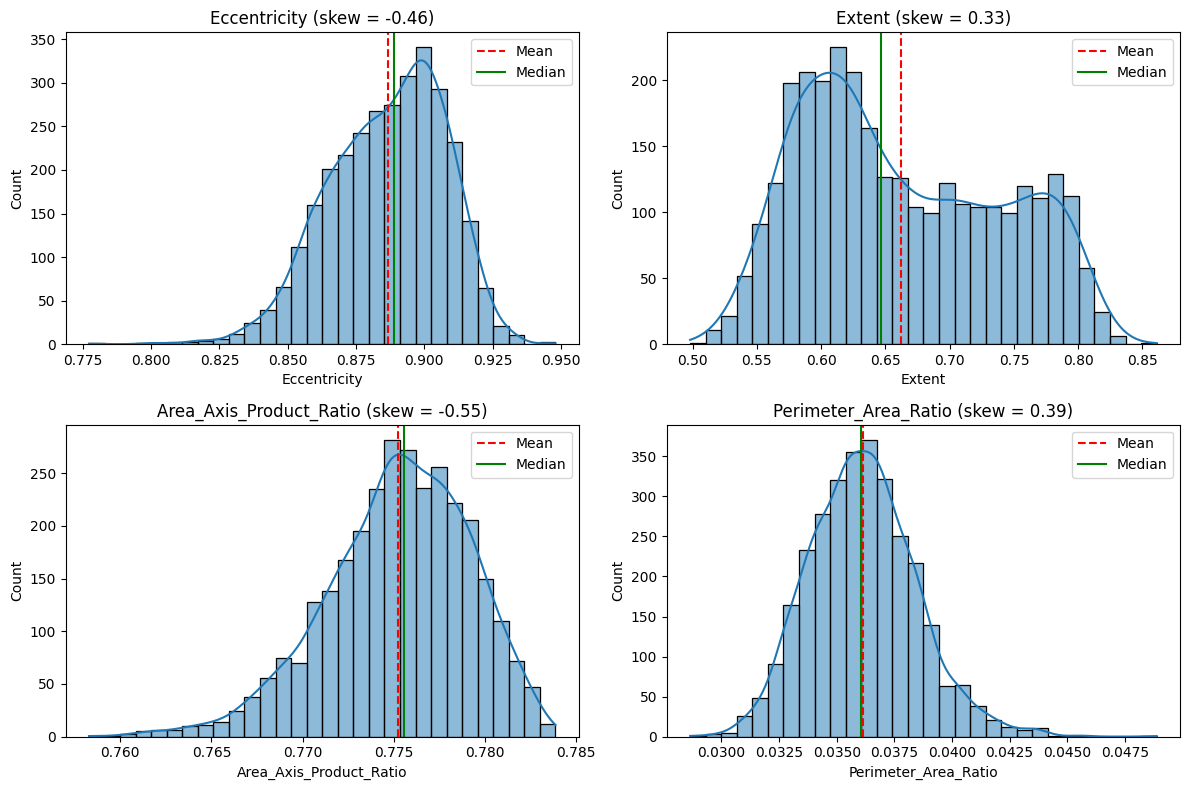

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, col in enumerate(X_train.columns):
    sns.histplot(X_train[col], kde=True, bins=30, ax=axes[i])
    axes[i].axvline(X_train[col].mean(), color='red', linestyle='--', label='Mean')
    axes[i].axvline(X_train[col].median(), color='green', linestyle='-', label='Median')
    axes[i].set_title(f"{col} (skew = {X_train[col].skew():.2f})")
    axes[i].legend()

plt.tight_layout()
plt.show()

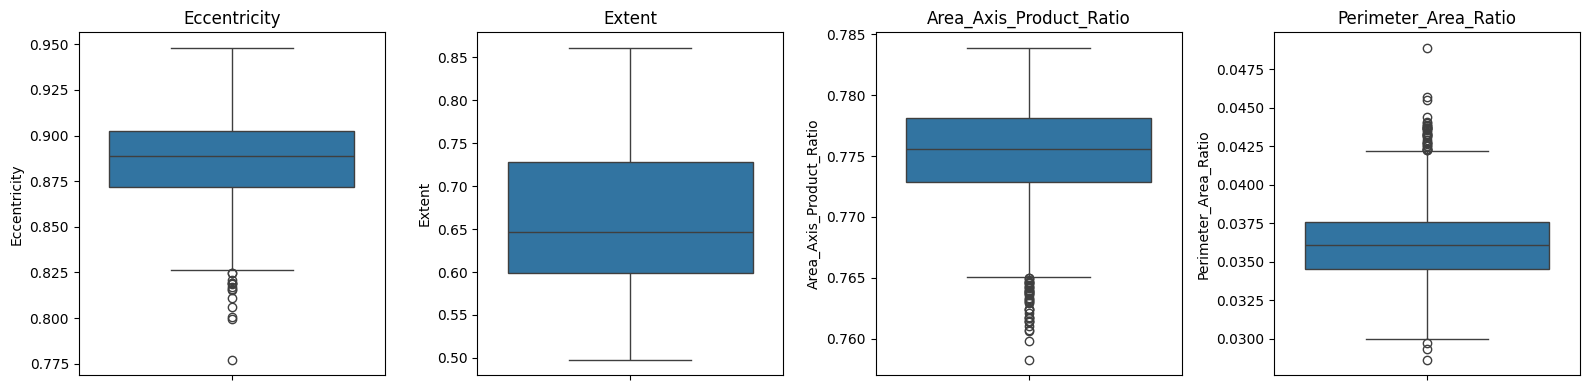

In [61]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, col in enumerate(X_train.columns):
    sns.boxplot(y=X_train[col], ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

##Final Observation before scaling:

* Eccentricity, Area_Axis_Product_Ratio and Perimeter_Area_Ratio have a small share of IQR-flagged outliers (0.46–1.31% of training rows).

* Area_Axis_Product_Ratio shows moderate negative skewness (see the skewness table above).

* Extent has low skewness, which by itself does not establish normality.


##Scaling decision
* Apply robust scaling for all features.
* To deal with the asymmetry, we use Box-Cox for Area_Axis_Product_Ratio since the feature has positive values only.
* Box-Cox reduces skewness; whether it improves prediction should be validated by CV with and without it.


##For Logistic Regression: Scaling

###Applying Robust scaling for all the features

In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, PowerTransformer

robust_cols  = ['Eccentricity', 'Extent', 'Perimeter_Area_Ratio']
boxcox_cols  = ['Area_Axis_Product_Ratio']

#Applying Box-Cox + RobustScaler
boxcox_robust = Pipeline([
    ('boxcox', PowerTransformer(method='box-cox', standardize=False)),
    ('robust', RobustScaler())
])

preprocessor_s2 = ColumnTransformer(
    transformers=[
        ('robust', RobustScaler(), robust_cols),
        ('boxcox_robust', boxcox_robust, boxcox_cols)
    ],
    remainder='drop'
)

In [63]:
X_train_s2 = preprocessor_s2.fit_transform(X_train)
X_test_s2  = preprocessor_s2.transform(X_test)

s2_cols = robust_cols + boxcox_cols
X_train_s2 = pd.DataFrame(X_train_s2, columns=s2_cols, index=X_train.index)
X_test_s2  = pd.DataFrame(X_test_s2,  columns=s2_cols, index=X_test.index)

lam = preprocessor_s2.named_transformers_['boxcox_robust'].named_steps['boxcox'].lambdas_
print("Area_Axis_Product_Ratio Box-Cox lambda:", lam)

print("\nArea_Axis_Product_Ratio skew before:", round(X_train['Area_Axis_Product_Ratio'].skew(), 4))
print("Area_Axis_Product_Ratio skew after :", round(X_train_s2['Area_Axis_Product_Ratio'].skew(), 4))

X_train_s2.describe().T

Area_Axis_Product_Ratio Box-Cox lambda: [38.32122052]

Area_Axis_Product_Ratio skew before: -0.5481
Area_Axis_Product_Ratio skew after : -0.0193


,count,mean,std,min,25%,50%,75%,max
Eccentricity,3048.0000,-0.0731,0.6821,-3.6226,-0.5563,0.0000,0.4437,1.9212
Extent,3048.0000,0.1217,0.5982,-1.1506,-0.3703,0.0000,0.6297,1.6590
Perimeter_Area_Ratio,3048.0000,0.0247,0.7535,-2.4098,-0.5069,-0.0000,0.4931,4.1666
Area_Axis_Product_Ratio,3048.0000,0.0142,0.7267,-2.2396,-0.4828,0.0000,0.5172,1.9624


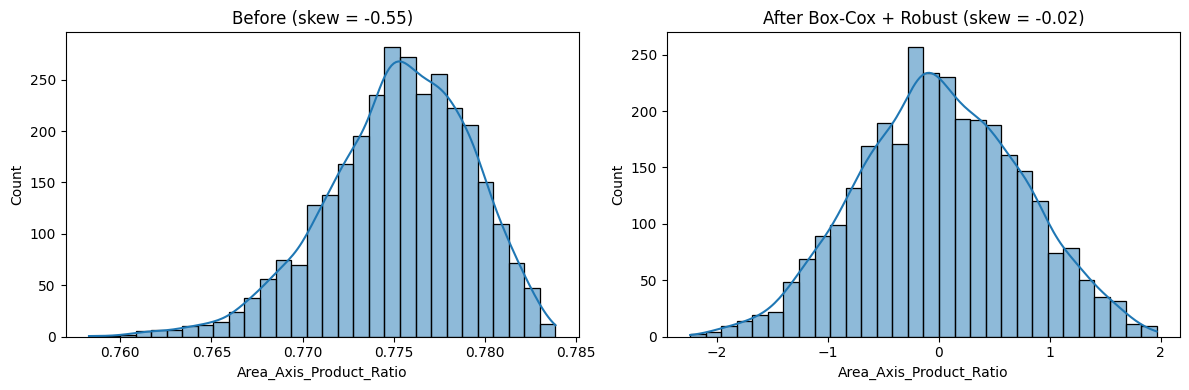

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train['Area_Axis_Product_Ratio'], kde=True, bins=30, ax=axes[0])
axes[0].set_title(f"Before (skew = {X_train['Area_Axis_Product_Ratio'].skew():.2f})")

sns.histplot(X_train_s2['Area_Axis_Product_Ratio'], kde=True, bins=30, ax=axes[1])
axes[1].set_title(f"After Box-Cox + Robust (skew = {X_train_s2['Area_Axis_Product_Ratio'].skew():.2f})")

plt.tight_layout()
plt.show()

###Sanity Check

Checking Nulls

In [65]:
print("X_train_s2 shape:", X_train_s2.shape, "| y_train:", y_train.shape)
print("X_test_s2  shape:", X_test_s2.shape,  "| y_test :", y_test.shape)

print("\nSame row count as y?:", len(X_train_s2) == len(y_train))
print("Index identical to X_train?:", X_train_s2.index.equals(X_train.index))
print("Missing values (train):\n", X_train_s2.isnull().sum())
print("Missing values (test) :", X_test_s2.isnull().sum().sum())
print("Inf values (train/test):",
      np.isinf(X_train_s2).sum().sum(), "/", np.isinf(X_test_s2).sum().sum())
print("\nDtypes:\n", X_train_s2.dtypes)

X_train_s2 shape: (3048, 4) | y_train: (3048,)
X_test_s2  shape: (762, 4) | y_test : (762,)

Same row count as y?: True
Index identical to X_train?: True
Missing values (train):
 Eccentricity               0
Extent                     0
Perimeter_Area_Ratio       0
Area_Axis_Product_Ratio    0
dtype: int64
Missing values (test) : 0
Inf values (train/test): 0 / 0

Dtypes:
 Eccentricity               float64
Extent                     float64
Perimeter_Area_Ratio       float64
Area_Axis_Product_Ratio    float64
dtype: object


Checking Whether the median=0, IQR=1 (Whether the scaler has fitted succesfully)

In [66]:
scale_check = pd.DataFrame({
    'Median': X_train_s2.median(),
    'Q1': X_train_s2.quantile(0.25),
    'Q3': X_train_s2.quantile(0.75),
    'IQR': X_train_s2.quantile(0.75) - X_train_s2.quantile(0.25),
    'Min': X_train_s2.min(),
    'Max': X_train_s2.max()
})
scale_check

,Median,Q1,Q3,IQR,Min,Max
Eccentricity,0.0000,-0.5563,0.4437,1.0000,-3.6226,1.9212
Extent,0.0000,-0.3703,0.6297,1.0000,-1.1506,1.6590
Perimeter_Area_Ratio,-0.0000,-0.5069,0.4931,1.0000,-2.4098,4.1666
Area_Axis_Product_Ratio,0.0000,-0.4828,0.5172,1.0000,-2.2396,1.9624


Checking whether the compactness skew has reduced

In [67]:
compare = pd.DataFrame({
    'Skew_Before': X_train.skew(),
    'Skew_After':  X_train_s2.skew(),
    'Kurt_After':  X_train_s2.kurt()
})
compare['Skew_Level_After'] = compare['Skew_After'].apply(skew_level)
display(compare)

display(iqr_outlier_summary(X_train_s2)[['Total_Outliers', 'Outlier_%']])

,Skew_Before,Skew_After,Kurt_After,Skew_Level_After
Area_Axis_Product_Ratio,-0.5481,-0.0193,-0.3039,Symmetric
Eccentricity,-0.4552,-0.4552,0.0897,Symmetric
Extent,0.3264,0.3264,-1.0573,Symmetric
Perimeter_Area_Ratio,0.3852,0.3852,0.6008,Symmetric


,Total_Outliers,Outlier_%
Feature,,
Eccentricity,14,0.4593
Extent,0,0.0000
Perimeter_Area_Ratio,37,1.2139
Area_Axis_Product_Ratio,5,0.1640


Histograms and boxplots

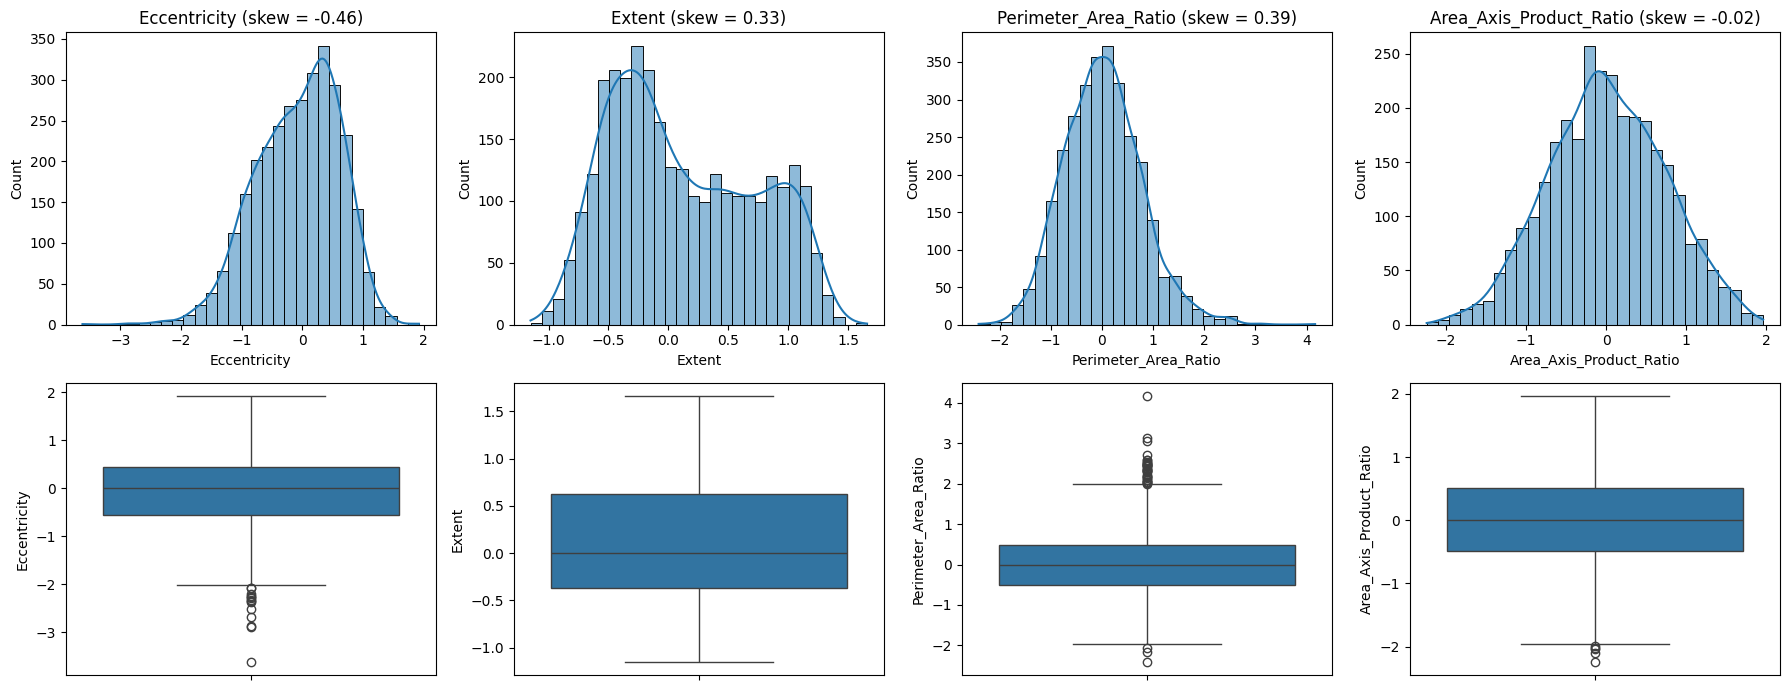

In [68]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(X_train_s2.columns):
    sns.histplot(X_train_s2[col], kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (skew = {X_train_s2[col].skew():.2f})")
    sns.boxplot(y=X_train_s2[col], ax=axes[1, i])
plt.tight_layout()
plt.show()

Checking the class balance

In [69]:
print("Train class proportions:", dict(zip(le.classes_, (np.bincount(y_train)/len(y_train)).round(3))))
print("Test class proportions :", dict(zip(le.classes_, (np.bincount(y_test)/len(y_test)).round(3))))

shift = pd.DataFrame({
    'Train_Mean': X_train_s2.mean(),
    'Test_Mean':  X_test_s2.mean(),
    'Train_Std':  X_train_s2.std(),
    'Test_Std':   X_test_s2.std()
})
shift

Train class proportions: {'Cammeo': np.float64(0.428), 'Osmancik': np.float64(0.572)}
Test class proportions : {'Cammeo': np.float64(0.428), 'Osmancik': np.float64(0.572)}


,Train_Mean,Test_Mean,Train_Std,Test_Std
Eccentricity,-0.0731,-0.0248,0.6821,0.6489
Extent,0.1217,0.1020,0.5982,0.5965
Perimeter_Area_Ratio,0.0247,0.0620,0.7535,0.7771
Area_Axis_Product_Ratio,0.0142,0.0330,0.7267,0.7330


##Validation setup

In [70]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = {}

In [71]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

def make_pipe(model):
    """Preprocessing is re-fitted inside every CV fold."""
    return Pipeline([("preprocess", clone(preprocessor_s2)), ("model", model)])

def clean_params(grid):
    """best_params_ without the 'model__' prefix (for rebuilding plain estimators)."""
    return {k.replace('model__', ''): v for k, v in grid.best_params_.items()}

In [72]:
param_grid_lr = {'model__C': [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=1000, random_state=42)),
    param_grid_lr, cv=cv, scoring='accuracy', n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print("Best params:", grid_lr.best_params_)
print("CV accuracy:", round(grid_lr.best_score_, 4))

idx = grid_lr.best_index_
cv_summary['Logistic Regression'] = (grid_lr.best_score_,
                                     grid_lr.cv_results_['std_test_score'][idx])

Best params: {'model__C': 10}
CV accuracy: 0.9272


In [73]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

dummy_rows = {}
for strategy in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strategy, random_state=42)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    dummy_rows[f'Dummy ({strategy})'] = {
        'Test Accuracy':     accuracy_score(y_test, y_pred_dummy),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_dummy),
        'Macro-F1':          f1_score(y_test, y_pred_dummy, average='macro'),
    }

pd.DataFrame(dummy_rows).T.round(4)

,Test Accuracy,Balanced Accuracy,Macro-F1
Dummy (most_frequent),0.5722,0.5000,0.3639
Dummy (stratified),0.4961,0.4850,0.4849


In [74]:
dummy_cv = cross_val_score(
    DummyClassifier(strategy='most_frequent'),
    X_train, y_train, cv=cv, scoring='accuracy'
)
cv_summary['Dummy (majority)'] = (dummy_cv.mean(), dummy_cv.std())

print("Dummy CV accuracy:", round(dummy_cv.mean(), 4), "+/-", round(dummy_cv.std(), 4))

Dummy CV accuracy: 0.5722 +/- 0.0005


###Logistic Regression

Accuracy : 0.9081
Precision: 0.9103
Recall   : 0.9312
F1       : 0.9206
ROC-AUC  : 0.9706

               precision    recall  f1-score   support

      Cammeo       0.91      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.91       762
weighted avg       0.91      0.91      0.91       762

Train accuracy: 0.9272
Test accuracy : 0.9081

Coefficients:
 Eccentricity              -4.7917
Perimeter_Area_Ratio       4.3585
Area_Axis_Product_Ratio    0.7517
Extent                     0.2028
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


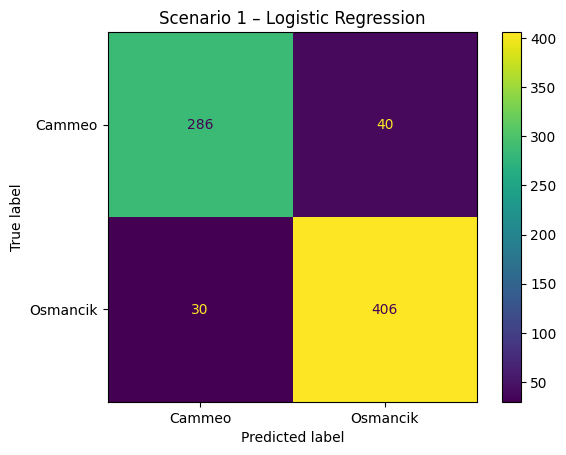

In [75]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

lr_best = grid_lr.best_estimator_
lr_s2   = lr_best.named_steps['model']
assert (lr_best.predict(X_test) == lr_s2.predict(X_test_s2)).all()

y_pred = lr_s2.predict(X_test_s2)
y_prob = lr_s2.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1       :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("\n", classification_report(y_test, y_pred, target_names=le.classes_))

# Train vs Test accuracy (overfitting check)
print("Train accuracy:", round(lr_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(lr_s2.score(X_test_s2, y_test), 4))

# Coefficients
coef = pd.Series(lr_s2.coef_[0], index=X_train_s2.columns).sort_values(key=abs, ascending=False)
print("\nCoefficients:\n", coef.round(4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_)
plt.title("Scenario 1 – Logistic Regression")
plt.show()

Sigmoid Chart

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


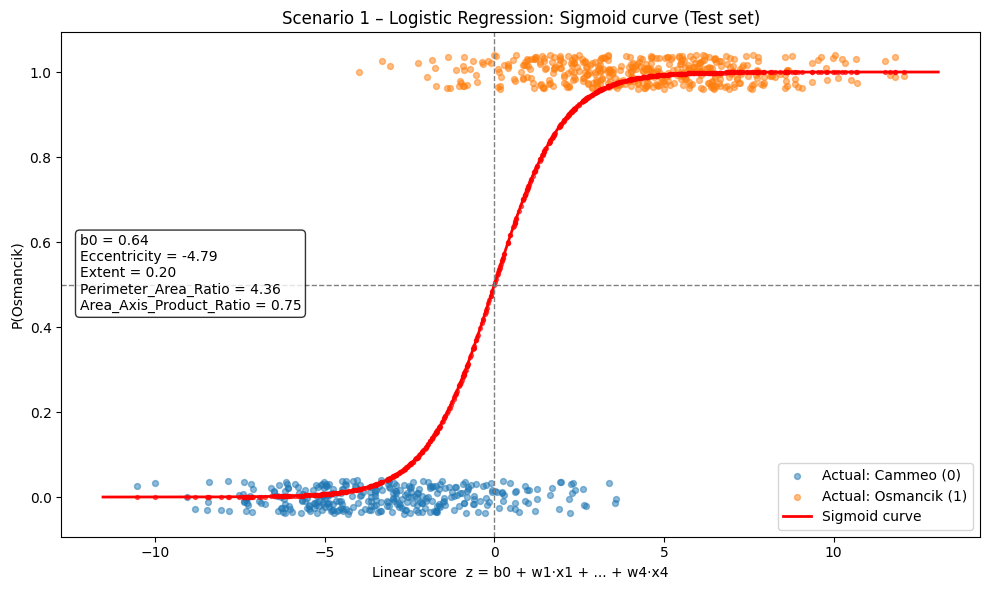

In [76]:
z_test = lr_s2.decision_function(X_test_s2)
p_test = lr_s2.predict_proba(X_test_s2)[:, 1]

z_line = np.linspace(z_test.min() - 1, z_test.max() + 1, 300)
p_line = 1 / (1 + np.exp(-z_line))

rng = np.random.RandomState(42)
y_jit = y_test + rng.uniform(-0.04, 0.04, size=len(y_test))

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(z_test[y_test == 0], y_jit[y_test == 0], color='tab:blue',   alpha=0.5, s=18, label='Actual: Cammeo (0)')
ax.scatter(z_test[y_test == 1], y_jit[y_test == 1], color='tab:orange', alpha=0.5, s=18, label='Actual: Osmancik (1)')

ax.plot(z_line, p_line, color='red', linewidth=2, label='Sigmoid curve')
ax.scatter(z_test, p_test, color='red', s=8, alpha=0.6)

ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)

ax.text(0.02, 0.60,
        f"b0 = {lr_s2.intercept_[0]:.2f}\n" +
        "\n".join([f"{c} = {w:.2f}" for c, w in zip(X_train_s2.columns, lr_s2.coef_[0])]),
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel("Linear score  z = b0 + w1·x1 + ... + w4·x4")
ax.set_ylabel("P(Osmancik)")
ax.set_title("Scenario 1 – Logistic Regression: Sigmoid curve (Test set)")
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

For Random Forest

###Validation


In [77]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_leaf': [1, 3, 5, 10],
}

grid_rf = GridSearchCV(
    make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    param_grid_rf, cv=cv, scoring='accuracy'
)
grid_rf.fit(X_train, y_train)

print("Best params:", grid_rf.best_params_)
print("CV accuracy:", round(grid_rf.best_score_, 4))

idx = grid_rf.best_index_
cv_summary['Random Forest'] = (grid_rf.best_score_,
                               grid_rf.cv_results_['std_test_score'][idx])

Best params: {'model__max_depth': 10, 'model__min_samples_leaf': 5}
CV accuracy: 0.9275


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Accuracy : 0.9055
Precision: 0.9044
Recall   : 0.9335
F1       : 0.9187
ROC-AUC  : 0.9669

               precision    recall  f1-score   support

      Cammeo       0.91      0.87      0.89       326
    Osmancik       0.90      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.90       762
weighted avg       0.91      0.91      0.91       762

Train accuracy: 0.9577
Test accuracy : 0.9055


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


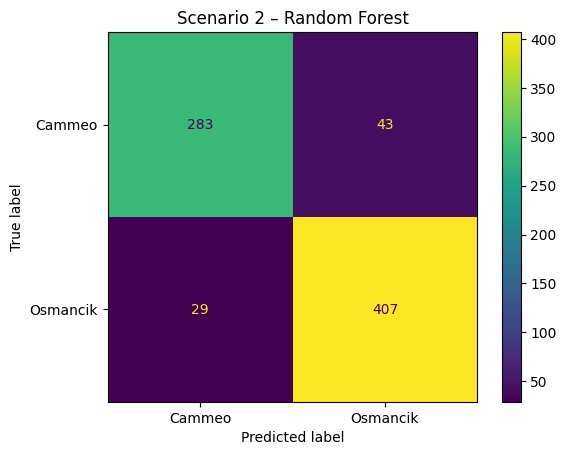

In [78]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

rf_s2 = grid_rf.best_estimator_.named_steps['model']
assert (grid_rf.best_estimator_.predict(X_test) == rf_s2.predict(X_test_s2)).all()

y_pred_rf = rf_s2.predict(X_test_s2)
y_prob_rf = rf_s2.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1       :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\n", classification_report(y_test, y_pred_rf, target_names=le.classes_))

print("Train accuracy:", round(rf_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(rf_s2.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=le.classes_)
plt.title("Scenario 2 – Random Forest")
plt.show()

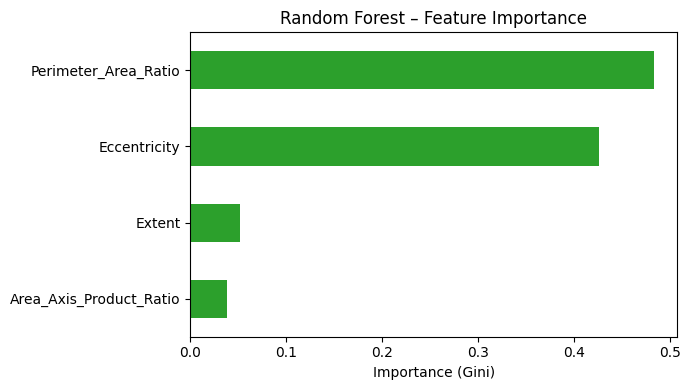

,0
Perimeter_Area_Ratio,0.4834
Eccentricity,0.4259
Extent,0.0520
Area_Axis_Product_Ratio,0.0387


In [79]:
imp = pd.Series(rf_s2.feature_importances_, index=X_train_s2.columns).sort_values()

plt.figure(figsize=(7, 4))
imp.plot(kind='barh', color='tab:green')
plt.xlabel("Importance (Gini)")
plt.title("Random Forest – Feature Importance")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest
Accuracy,0.9081,0.9055
Precision,0.9103,0.9044
Recall,0.9312,0.9335
F1,0.9206,0.9187
ROC-AUC,0.9706,0.9669
Train Accuracy,0.9272,0.9577


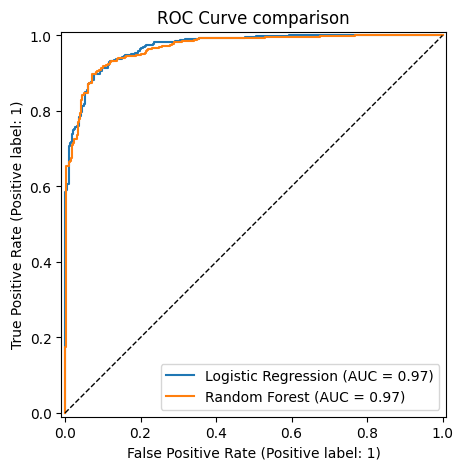

In [80]:
results = pd.DataFrame({
    'Logistic Regression': [
        accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
        recall_score(y_test, y_pred), f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob), lr_s2.score(X_train_s2, y_train)],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_prob_rf), rf_s2.score(X_train_s2, y_train)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Train Accuracy']).round(4)
display(results)

# ROC curves
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_prob,    name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_prob_rf, name='Random Forest', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_title("ROC Curve comparison")
plt.show()

##K-Nearest Neighbours

In [81]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_s2, y_train)

print("Baseline k=5 | Train acc:", round(knn_base.score(X_train_s2, y_train), 4),
      "| Test acc:", round(knn_base.score(X_test_s2, y_test), 4))

Baseline k=5 | Train acc: 0.9373 | Test acc: 0.9016


In [82]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = range(1, 32, 2)

knn_fold_scores = {}
for k in k_values:
    pipe = make_pipe(KNeighborsClassifier(n_neighbors=k))
    knn_fold_scores[k] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')

cv_scores = [knn_fold_scores[k].mean() for k in k_values]
cv_stds   = [knn_fold_scores[k].std()  for k in k_values]
best_k    = list(k_values)[int(np.argmax(cv_scores))]
print("Best k:", best_k, "| CV accuracy:", round(max(cv_scores), 4),
      "| CV std:", round(cv_stds[list(k_values).index(best_k)], 4))

Best k: 29 | CV accuracy: 0.9236 | CV std: 0.0074


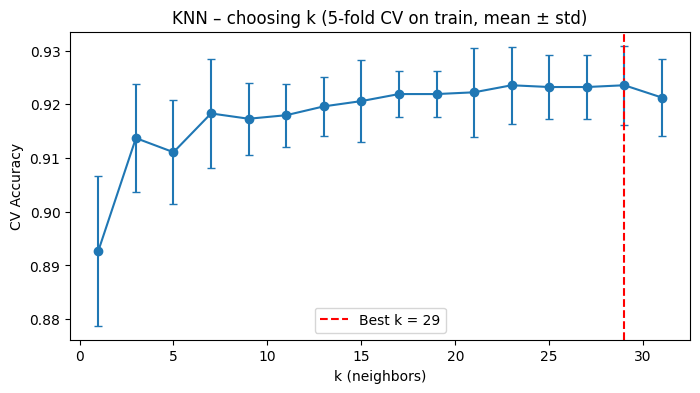

In [83]:
plt.figure(figsize=(8, 4))
plt.errorbar(list(k_values), cv_scores, yerr=cv_stds, marker='o', capsize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel("k (neighbors)"); plt.ylabel("CV Accuracy")
plt.title("KNN – choosing k (5-fold CV on train, mean ± std)")
plt.legend(); plt.show()

Accuracy : 0.899
Precision: 0.9016
Recall   : 0.9243
F1       : 0.9128
ROC-AUC  : 0.9658

               precision    recall  f1-score   support

      Cammeo       0.90      0.87      0.88       326
    Osmancik       0.90      0.92      0.91       436

    accuracy                           0.90       762
   macro avg       0.90      0.89      0.90       762
weighted avg       0.90      0.90      0.90       762

Train accuracy: 0.9268
Test accuracy : 0.899


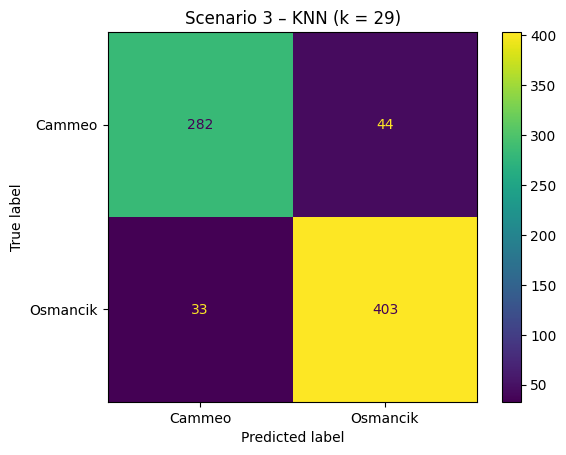

In [84]:
knn_s3 = KNeighborsClassifier(n_neighbors=best_k)
knn_s3.fit(X_train_s2, y_train)

y_pred_knn = knn_s3.predict(X_test_s2)
y_prob_knn = knn_s3.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_knn), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn), 4))
print("Recall   :", round(recall_score(y_test, y_pred_knn), 4))
print("F1       :", round(f1_score(y_test, y_pred_knn), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_knn), 4))
print("\n", classification_report(y_test, y_pred_knn, target_names=le.classes_))

print("Train accuracy:", round(knn_s3.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(knn_s3.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=le.classes_)
plt.title(f"Scenario 3 – KNN (k = {best_k})")
plt.show()

In [85]:
from sklearn.neighbors import KNeighborsClassifier

f1, f2 = 'Eccentricity', 'Perimeter_Area_Ratio'
X2_train = X_train_s2[[f1, f2]]

knn_2d = KNeighborsClassifier(n_neighbors=best_k)
knn_2d.fit(X2_train, y_train)

xx, yy = np.meshgrid(
    np.linspace(X2_train[f1].min() - 0.5, X2_train[f1].max() + 0.5, 300),
    np.linspace(X2_train[f2].min() - 0.5, X2_train[f2].max() + 0.5, 300)
)
grid_2d = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
zz = knn_2d.predict(grid_2d).reshape(xx.shape)

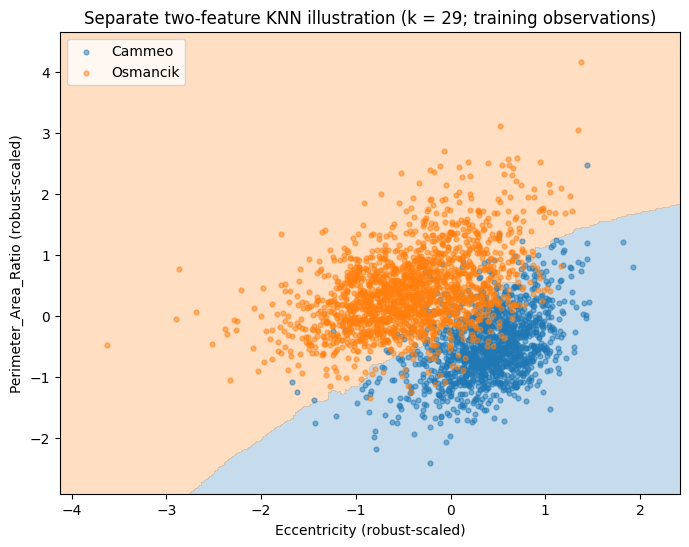

In [86]:
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.25,
             colors=['tab:blue', 'tab:orange'])

for cls_id, cls_name in enumerate(le.classes_):
    mask = (y_train == cls_id)
    plt.scatter(X2_train.loc[mask, f1], X2_train.loc[mask, f2],
                s=12, alpha=0.5, label=cls_name)

plt.xlabel(f"{f1} (robust-scaled)"); plt.ylabel(f"{f2} (robust-scaled)")
plt.title(f"Separate two-feature KNN illustration (k = {best_k}; training observations)")
plt.legend()
plt.show()

##Support Vector Machines

###RBF SVM tuning

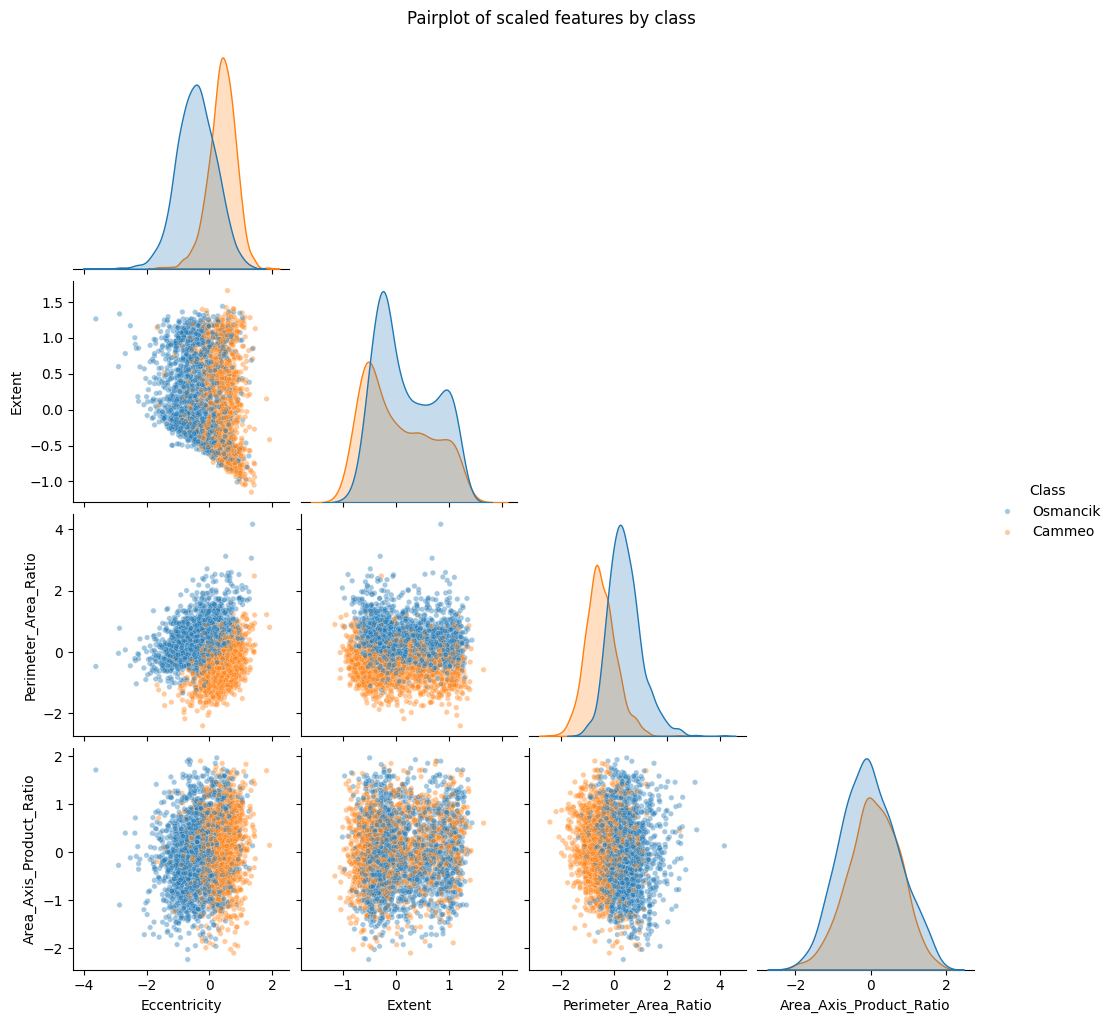

In [87]:
eda_df = X_train_s2.copy()
eda_df['Class'] = le.inverse_transform(y_train)

sns.pairplot(eda_df, hue='Class', corner=True,
             plot_kws={'alpha': 0.4, 's': 15}, diag_kind='kde')
plt.suptitle("Pairplot of scaled features by class", y=1.02)
plt.show()

Explained variance ratio: [0.34  0.272] | Total: 0.612


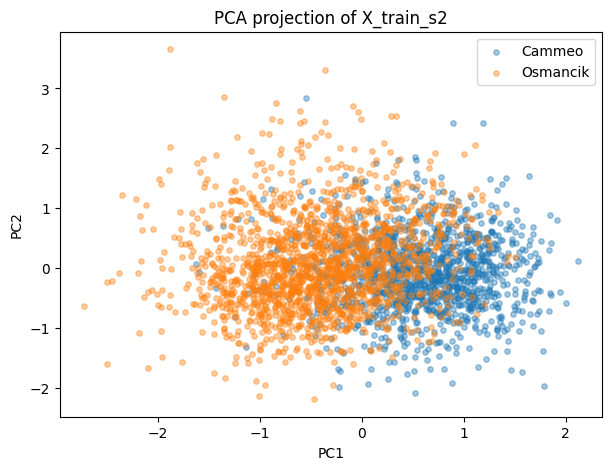

In [88]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_train_s2)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| Total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
for cls_id, cls_name in enumerate(le.classes_):
    plt.scatter(Z[y_train == cls_id, 0], Z[y_train == cls_id, 1],
                alpha=0.4, s=15, label=cls_name)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA projection of X_train_s2")
plt.legend()
plt.show()

In [89]:
from sklearn.svm import SVC

param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.1, 1],
}

grid_svm = GridSearchCV(
    make_pipe(SVC(kernel='rbf', random_state=42)),
    param_grid_svm, cv=cv, scoring='accuracy', n_jobs=-1
)
grid_svm.fit(X_train, y_train)

print("Best params:", grid_svm.best_params_)
print("CV accuracy:", round(grid_svm.best_score_, 4))

idx = grid_svm.best_index_
cv_summary['SVM'] = (grid_svm.best_score_, grid_svm.cv_results_['std_test_score'][idx])

Best params: {'model__C': 1, 'model__gamma': 0.1}
CV accuracy: 0.9295


Accuracy : 0.9081
Precision: 0.9122
Recall   : 0.9289
F1       : 0.9205
ROC-AUC  : 0.9702

               precision    recall  f1-score   support

      Cammeo       0.90      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.91       762
weighted avg       0.91      0.91      0.91       762



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Train accuracy: 0.9301
Test accuracy : 0.9081


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


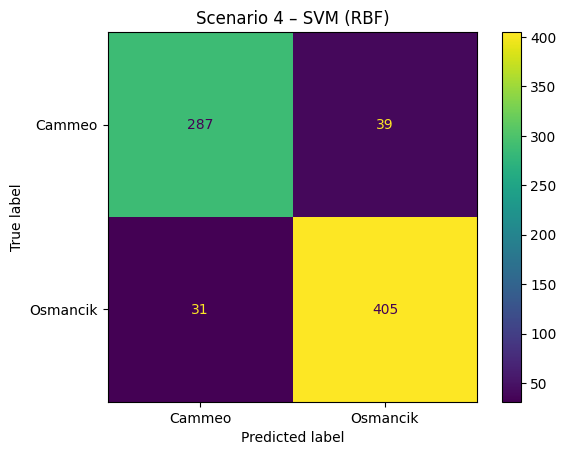

In [90]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

svm_s2 = grid_svm.best_estimator_.named_steps['model']
assert (grid_svm.best_estimator_.predict(X_test) == svm_s2.predict(X_test_s2)).all()

y_pred_svm = svm_s2.predict(X_test_s2)
y_score_svm = svm_s2.decision_function(X_test_s2)

print("Accuracy :", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall   :", round(recall_score(y_test, y_pred_svm), 4))
print("F1       :", round(f1_score(y_test, y_pred_svm), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_score_svm), 4))
print("\n", classification_report(y_test, y_pred_svm, target_names=le.classes_))

print("Train accuracy:", round(svm_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(svm_s2.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, display_labels=le.classes_)
plt.title("Scenario 4 – SVM (RBF)")
plt.show()

In [91]:
n_sv = svm_s2.n_support_
print("Support vectors per class:", dict(zip(le.classes_, n_sv)))
print("Total SV:", n_sv.sum(), "| % of train:", round(100 * n_sv.sum() / len(X_train_s2), 2), "%")

Support vectors per class: {'Cammeo': np.int32(329), 'Osmancik': np.int32(330)}
Total SV: 659 | % of train: 21.62 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


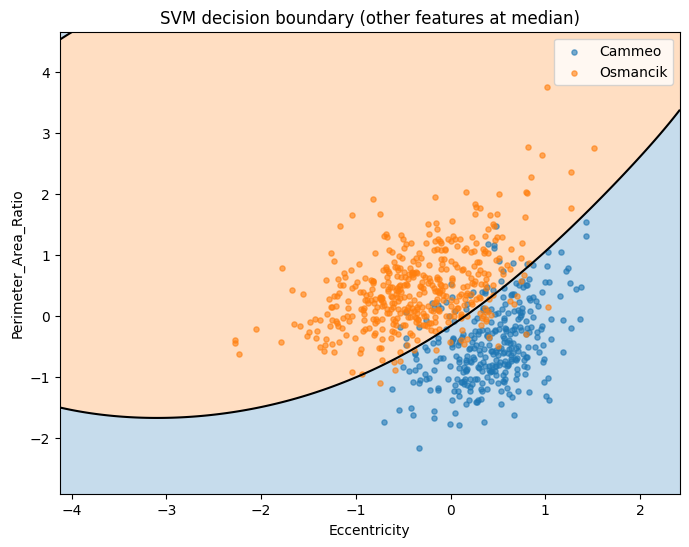

In [92]:
f1, f2 = 'Eccentricity', 'Perimeter_Area_Ratio'
xx, yy = np.meshgrid(np.linspace(X_train_s2[f1].min()-0.5, X_train_s2[f1].max()+0.5, 300),
                     np.linspace(X_train_s2[f2].min()-0.5, X_train_s2[f2].max()+0.5, 300))

grid_df = pd.DataFrame({c: np.full(xx.size, X_train_s2[c].median()) for c in X_train_s2.columns})
grid_df[f1], grid_df[f2] = xx.ravel(), yy.ravel()
zz = svm_s2.decision_function(grid_df).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=[-100, 0, 100], alpha=0.25, colors=['tab:blue', 'tab:orange'])
plt.contour(xx, yy, zz, levels=[0], colors='k', linewidths=1.5)
for cls_id, cls_name in enumerate(le.classes_):
    m = y_test == cls_id
    plt.scatter(X_test_s2.loc[m, f1] if hasattr(X_test_s2, 'loc') else X_test_s2[m, 0],
                X_test_s2.loc[m, f2] if hasattr(X_test_s2, 'loc') else X_test_s2[m, 1],
                s=14, alpha=0.6, label=cls_name)
plt.xlabel(f1); plt.ylabel(f2)
plt.title("SVM decision boundary (other features at median)")
plt.legend()
plt.show()

##Model Comparison

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest,KNN (k=29),SVM (RBF)
Accuracy,0.9081,0.9055,0.8990,0.9081
Precision,0.9103,0.9044,0.9016,0.9122
Recall,0.9312,0.9335,0.9243,0.9289
F1,0.9206,0.9187,0.9128,0.9205
ROC-AUC,0.9706,0.9669,0.9658,0.9702
Train Accuracy,0.9272,0.9577,0.9268,0.9301


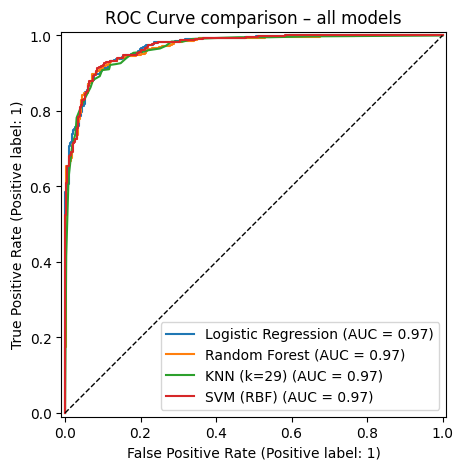

In [93]:
from sklearn.metrics import RocCurveDisplay

models = {
    'Logistic Regression': (y_pred,     y_prob,      lr_s2),
    'Random Forest':       (y_pred_rf,  y_prob_rf,   rf_s2),
    f'KNN (k={best_k})':   (y_pred_knn, y_prob_knn,  knn_s3),
    'SVM (RBF)':           (y_pred_svm, y_score_svm, svm_s2),
}

rows = {}
for name, (yp, ysc, mdl) in models.items():
    rows[name] = [accuracy_score(y_test, yp), precision_score(y_test, yp),
                  recall_score(y_test, yp), f1_score(y_test, yp),
                  roc_auc_score(y_test, ysc), mdl.score(X_train_s2, y_train)]

results = pd.DataFrame(rows, index=['Accuracy','Precision','Recall','F1','ROC-AUC','Train Accuracy']).round(4)
display(results)

fig, ax = plt.subplots(figsize=(6, 5))
for name, (yp, ysc, mdl) in models.items():
    RocCurveDisplay.from_predictions(y_test, ysc, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_title("ROC Curve comparison – all models")
plt.show()

In [94]:
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

def extra_metrics(yp):
    return [balanced_accuracy_score(y_test, yp),
            f1_score(y_test, yp, average='macro'),
            recall_score(y_test, yp, pos_label=0),
            recall_score(y_test, yp, pos_label=1)]

extra = {name: extra_metrics(yp) for name, (yp, ysc, mdl) in models.items()}
y_pred_majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train).predict(X_test)
extra['Dummy (majority)'] = extra_metrics(y_pred_majority)

pd.DataFrame(extra, index=['Balanced Acc', 'Macro-F1',
                           f'Recall {le.classes_[0]}', f'Recall {le.classes_[1]}']).T.round(4)

,Balanced Acc,Macro-F1,Recall Cammeo,Recall Osmancik
Logistic Regression,0.9042,0.9058,0.8773,0.9312
Random Forest,0.9008,0.9029,0.8681,0.9335
KNN (k=29),0.8947,0.8963,0.8650,0.9243
SVM (RBF),0.9046,0.9059,0.8804,0.9289
Dummy (majority),0.5000,0.3639,0.0000,1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature n

,Train Accuracy,Test Accuracy,Gap (Train - Test)
Logistic Regression,0.9272,0.9081,0.0190
Random Forest,0.9577,0.9055,0.0522
KNN (k=29),0.9268,0.8990,0.0279
SVM (RBF),0.9301,0.9081,0.0220


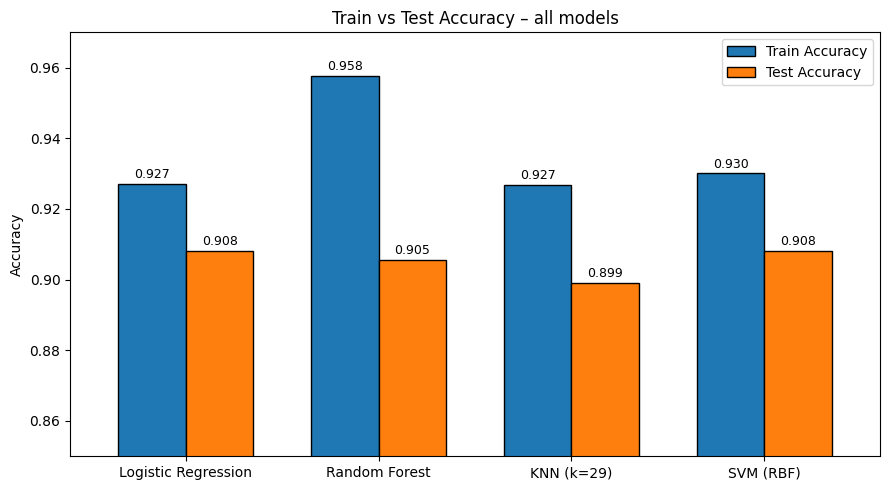

In [95]:
models_acc = {
    'Logistic Regression': lr_s2,
    'Random Forest':       rf_s2,
    f'KNN (k={best_k})':   knn_s3,
    'SVM (RBF)':           svm_s2,
}

acc_df = pd.DataFrame({
    'Train Accuracy': {n: m.score(X_train_s2, y_train) for n, m in models_acc.items()},
    'Test Accuracy':  {n: m.score(X_test_s2,  y_test)  for n, m in models_acc.items()},
})
acc_df['Gap (Train - Test)'] = acc_df['Train Accuracy'] - acc_df['Test Accuracy']
acc_df = acc_df.round(4)
display(acc_df)


ax = acc_df[['Train Accuracy', 'Test Accuracy']].plot(
    kind='bar', figsize=(9, 5), width=0.7, color=['tab:blue', 'tab:orange'], edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=9)

ax.set_ylim(0.85, 0.97)
ax.set_ylabel("Accuracy")
ax.set_title("Train vs Test Accuracy – all models")
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

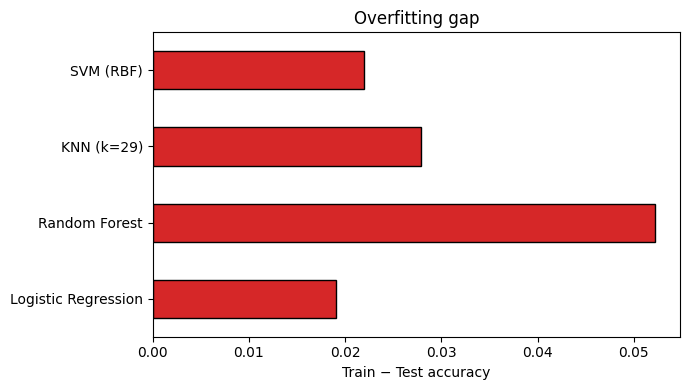

In [96]:
plt.figure(figsize=(7, 4))
acc_df['Gap (Train - Test)'].plot(kind='barh', color='tab:red', edgecolor='black')
plt.xlabel("Train − Test accuracy")
plt.title("Overfitting gap")
plt.tight_layout()
plt.show()

Random Forest has the largest training–test accuracy gap in this experiment, suggesting greater overfitting risk. Cross-validation results and learning curves are needed for further assessment.

In [97]:
knn_idx = list(k_values).index(best_k)
cv_summary['KNN'] = (cv_scores[knn_idx], cv_stds[knn_idx])

pd.DataFrame(cv_summary, index=['CV mean acc', 'CV std']).T.round(4)

,CV mean acc,CV std
Logistic Regression,0.9272,0.0045
Dummy (majority),0.5722,0.0005
Random Forest,0.9275,0.0070
SVM,0.9295,0.0055
KNN,0.9236,0.0074


##Original measurements vs engineered features

In [98]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, PowerTransformer

orig_features = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
                 'Eccentricity', 'Convex_Area', 'Extent']

# Raw measurements + the two engineered ratios, all on the SAME rows as the existing split
df_all = df.copy()
df_all['Perimeter_Area_Ratio'] = df_all['Perimeter'] / df_all['Area']
df_all['Area_Axis_Product_Ratio'] = df_all['Area'] / (df_all['Major_Axis_Length'] * df_all['Minor_Axis_Length'])

train_idx, test_idx = X_train.index, X_test.index

# Sanity check: the labels line up with the existing y_train / y_test
assert (le.transform(df_all.loc[train_idx, target_col]) == y_train).all()
assert (le.transform(df_all.loc[test_idx,  target_col]) == y_test).all()
print("Rows aligned with the existing split.")

Rows aligned with the existing split.


In [99]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def vif_prune(frame, threshold=10):
    """Repeatedly drop the feature with the highest VIF until all VIF <= threshold."""
    cols = list(frame.columns)
    while len(cols) > 1:
        Xv = add_constant(frame[cols])
        vifs = pd.Series([variance_inflation_factor(Xv.values, i + 1) for i in range(len(cols))],
                         index=cols)
        if vifs.max() <= threshold:
            break
        cols.remove(vifs.idxmax())
    return cols, vifs

# TRAINING rows only, so the selection does not see the test set
vif_cols, vif_final = vif_prune(df_all.loc[train_idx, orig_features])
print("Original features kept after VIF pruning:", vif_cols)
vif_final.round(2)

Original features kept after VIF pruning: ['Minor_Axis_Length', 'Eccentricity', 'Extent']


,0
Minor_Axis_Length,1.0900
Eccentricity,1.1400
Extent,1.0400


*Exploratory fixed candidate:* this VIF pruning runs outside cross-validation, so the selection has a
limitation, and low VIF alone does not make this subset the recommended one.

In [100]:
def make_preprocessor(cols):
    """Same logic as preprocessor_s2: RobustScaler everywhere,
    Box-Cox + RobustScaler on Area_Axis_Product_Ratio (only if Area_Axis_Product_Ratio is in cols)."""
    plain = [c for c in cols if c != 'Area_Axis_Product_Ratio']
    transformers = []
    if plain:
        transformers.append(('robust', RobustScaler(), plain))
    if 'Area_Axis_Product_Ratio' in cols:
        transformers.append(('boxcox_robust',
                             Pipeline([('boxcox', PowerTransformer(method='box-cox', standardize=False)),
                                       ('robust', RobustScaler())]),
                             ['Area_Axis_Product_Ratio']))
    return ColumnTransformer(transformers, remainder='drop')

feature_sets = {
    'A: all 7 original':                      orig_features,
    'B: 6 originals behind the 4 engineered': ['Eccentricity', 'Extent', 'Area',
                                               'Major_Axis_Length', 'Minor_Axis_Length', 'Perimeter'],
    'C: VIF-pruned originals (train only)':   vif_cols,
    'D: 4 engineered (current)':              keep_cols,
}

for name, cols in feature_sets.items():
    print(f"{name:<42} {len(cols)} features")

A: all 7 original                          7 features
B: 6 originals behind the 4 engineered     6 features
C: VIF-pruned originals (train only)       3 features
D: 4 engineered (current)                  4 features


### Comparison under fixed hyperparameter settings
Hyperparameters tuned for one feature set are reused for every set below. The retuned comparison for the
final shortlist is in the reduced-subset section of the main analysis.

In [101]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

# Hyper-parameters reused from the earlier tuning (see note below the table)
model_factories = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=1000, random_state=42, **clean_params(grid_lr)),
    'Random Forest':       lambda: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, **clean_params(grid_rf)),
    f'KNN (k={best_k})':   lambda: KNeighborsClassifier(n_neighbors=best_k),
    'SVM (RBF)':           lambda: SVC(kernel='rbf', random_state=42, **clean_params(grid_svm)),
}

rows = []
for set_name, cols in feature_sets.items():
    Xtr, Xte = df_all.loc[train_idx, cols], df_all.loc[test_idx, cols]
    for model_name, make_model in model_factories.items():
        pipe = Pipeline([('prep', make_preprocessor(cols)), ('model', make_model())])

        cvr = cross_validate(pipe, Xtr, y_train, cv=cv,
                             scoring=['accuracy', 'f1_macro', 'balanced_accuracy'])
        pipe.fit(Xtr, y_train)
        yp = pipe.predict(Xte)

        rows.append({
            'Feature set': set_name, 'Model': model_name, 'n_features': len(cols),
            'CV Acc (mean)': cvr['test_accuracy'].mean(),
            'CV Acc (std)':  cvr['test_accuracy'].std(),
            'Test Acc':      accuracy_score(y_test, yp),
            'Test Balanced Acc': balanced_accuracy_score(y_test, yp),
            'Test Macro-F1': f1_score(y_test, yp, average='macro'),
        })

fs_results = pd.DataFrame(rows)
fs_results.round(4)

,Feature set,Model,n_features,CV Acc (mean),CV Acc (std),Test Acc,Test Balanced Acc,Test Macro-F1
0,A: all 7 original,Logistic Regression,7,0.9331,0.0086,0.9173,0.9134,0.9152
1,A: all 7 original,Random Forest,7,0.9272,0.0091,0.9160,0.9111,0.9136
2,A: all 7 original,KNN (k=29),7,0.9304,0.0101,0.9055,0.9012,0.9030
3,A: all 7 original,SVM (RBF),7,0.9321,0.0103,0.9147,0.9104,0.9124
4,B: 6 originals behind the 4 engineered,Logistic Regression,6,0.9314,0.0088,0.9147,0.9111,0.9126
5,B: 6 originals behind the 4 engineered,Random Forest,6,0.9265,0.0094,0.9199,0.9153,0.9177
6,B: 6 originals behind the 4 engineered,KNN (k=29),6,0.9304,0.0109,0.9094,0.9054,0.9071
7,B: 6 originals behind the 4 engineered,SVM (RBF),6,0.9308,0.0102,0.9147,0.9108,0.9125
8,C: VIF-pruned originals (train only),Logistic Regression,3,0.9311,0.0081,0.9121,0.9088,0.9100
9,C: VIF-pruned originals (train only),Random Forest,3,0.9203,0.0086,0.9094,0.9050,0.9070


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
A: all 7 original,0.9304,0.9331,0.9272,0.9321
B: 6 originals behind the 4 engineered,0.9304,0.9314,0.9265,0.9308
C: VIF-pruned originals (train only),0.9272,0.9311,0.9203,0.9327
D: 4 engineered (current),0.9236,0.9272,0.9275,0.9295


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
A: all 7 original,0.9055,0.9173,0.9160,0.9147
B: 6 originals behind the 4 engineered,0.9094,0.9147,0.9199,0.9147
C: VIF-pruned originals (train only),0.9094,0.9121,0.9094,0.9147
D: 4 engineered (current),0.8990,0.9081,0.9055,0.9081


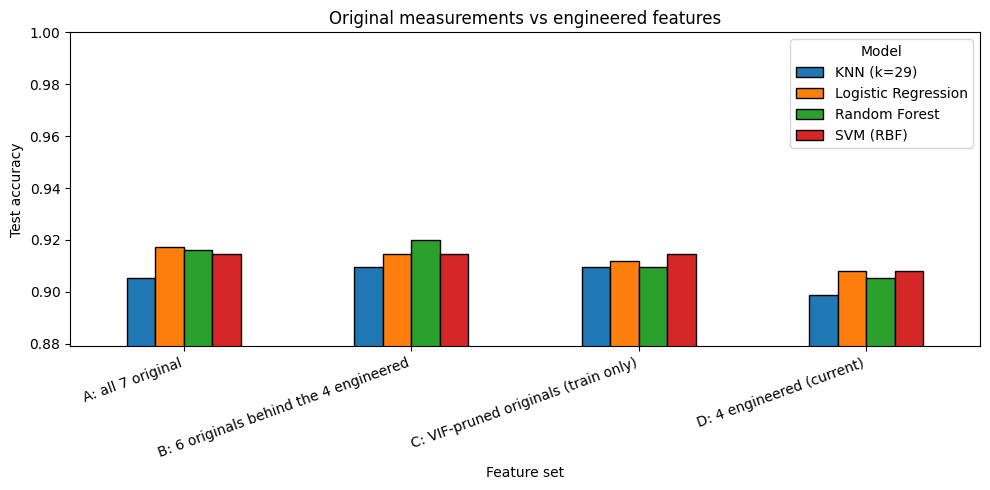

In [102]:
display(fs_results.pivot(index='Feature set', columns='Model', values='CV Acc (mean)').round(4))
display(fs_results.pivot(index='Feature set', columns='Model', values='Test Acc').round(4))

ax = fs_results.pivot(index='Feature set', columns='Model', values='Test Acc').plot(
    kind='bar', figsize=(10, 5), edgecolor='black')
ax.set_ylabel("Test accuracy")
ax.set_ylim(fs_results['Test Acc'].min() - 0.02, 1.0)
ax.set_title("Original measurements vs engineered features")
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

##Feature importance (Permutation, SHAP, fold stability)

In [103]:
from sklearn.inspection import permutation_importance

fitted_models = {
    'Logistic Regression': lr_s2,
    'Random Forest':       rf_s2,
    f'KNN (k={best_k})':   knn_s3,
    'SVM (RBF)':           svm_s2,
}

perm_mean, perm_std = {}, {}
for name, mdl in fitted_models.items():
    r = permutation_importance(mdl, X_test_s2, y_test, scoring='accuracy',
                               n_repeats=30, random_state=42, n_jobs=-1)
    perm_mean[name] = pd.Series(r.importances_mean, index=X_test_s2.columns)
    perm_std[name]  = pd.Series(r.importances_std,  index=X_test_s2.columns)

perm_df = pd.DataFrame(perm_mean)
perm_df.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest,KNN (k=29),SVM (RBF)
Eccentricity,0.2238,0.2023,0.2073,0.2163
Extent,0.0021,0.0022,-0.0026,-0.0002
Perimeter_Area_Ratio,0.2377,0.2465,0.2326,0.2444
Area_Axis_Product_Ratio,0.0035,-0.0030,-0.0009,0.0023


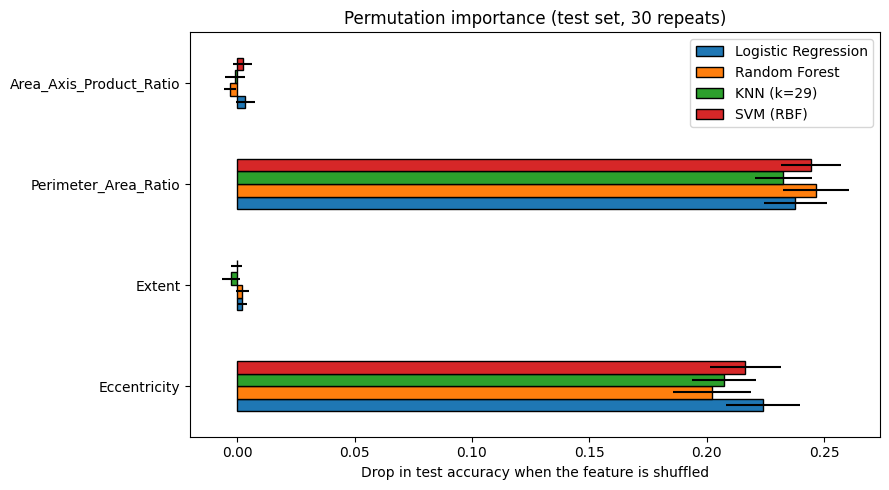

In [104]:
ax = perm_df.plot(kind='barh', figsize=(9, 5), edgecolor='black',
                  xerr=pd.DataFrame(perm_std))
ax.set_xlabel("Drop in test accuracy when the feature is shuffled")
ax.set_title("Permutation importance (test set, 30 repeats)")
plt.tight_layout()
plt.show()

In [105]:
!pip install -q shap

In [106]:
import shap

def positive_class_shap(sv):
    """Return SHAP values for class 1 (Osmancik) regardless of the shap version's output shape."""
    if isinstance(sv, list):
        return sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

# Random Forest (tree explainer)
shap_rf = positive_class_shap(shap.TreeExplainer(rf_s2).shap_values(X_test_s2))

# Logistic Regression (linear explainer)
shap_lr = shap.LinearExplainer(lr_s2, X_train_s2).shap_values(X_test_s2)

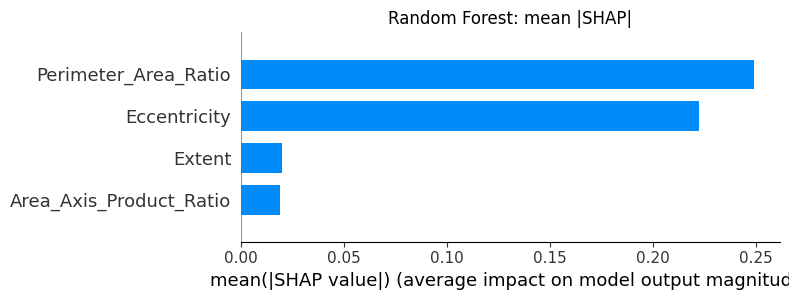

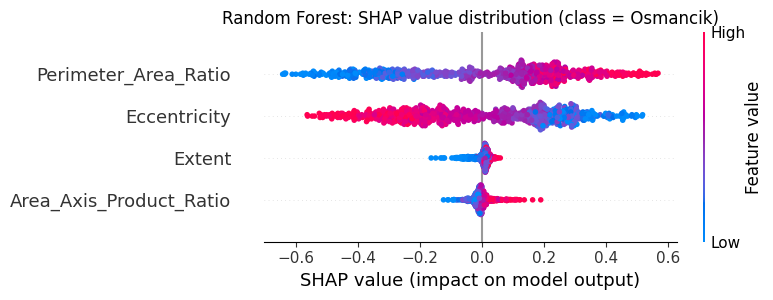

In [107]:
shap.summary_plot(shap_rf, X_test_s2, plot_type='bar', show=False)
plt.title("Random Forest: mean |SHAP|")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_rf, X_test_s2, show=False)
plt.title("Random Forest: SHAP value distribution (class = Osmancik)")
plt.tight_layout()
plt.show()

In [108]:
shap_table = pd.DataFrame({
    'RF mean |SHAP|': np.abs(shap_rf).mean(axis=0),
    'LR mean |SHAP|': np.abs(shap_lr).mean(axis=0),
}, index=X_test_s2.columns)
shap_table['RF rank'] = shap_table['RF mean |SHAP|'].rank(ascending=False).astype(int)
shap_table['LR rank'] = shap_table['LR mean |SHAP|'].rank(ascending=False).astype(int)
shap_table.sort_values('RF rank').round(4)

,RF mean |SHAP|,LR mean |SHAP|,RF rank,LR rank
Perimeter_Area_Ratio,0.2494,2.6621,1,1
Eccentricity,0.2226,2.6452,2,2
Extent,0.0200,0.1030,3,4
Area_Axis_Product_Ratio,0.0192,0.4325,4,3


In [109]:
from scipy.stats import spearmanr
from itertools import combinations

fold_imp = {}
for k, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    pipe = Pipeline([
        ('prep',  clone(preprocessor_s2)),
        ('model', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, **clean_params(grid_rf))),
    ])
    pipe.fit(X_train.iloc[tr], y_train[tr])
    r = permutation_importance(pipe, X_train.iloc[va], y_train[va], scoring='accuracy',
                               n_repeats=20, random_state=42, n_jobs=-1)
    fold_imp[f'Fold {k}'] = pd.Series(r.importances_mean, index=X_train.columns)

fold_imp  = pd.DataFrame(fold_imp)
fold_rank = fold_imp.rank(ascending=False).astype(int)

display(fold_imp.round(4))
display(fold_rank)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Eccentricity,0.2228,0.2191,0.2211,0.2239,0.2374
Extent,0.0051,0.0020,0.0076,0.0063,-0.0032
Area_Axis_Product_Ratio,0.0044,0.0085,0.0087,0.0087,0.0011
Perimeter_Area_Ratio,0.2359,0.2586,0.2676,0.2472,0.2373


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Eccentricity,2,2,2,2,1
Extent,3,4,4,4,4
Area_Axis_Product_Ratio,4,3,3,3,3
Perimeter_Area_Ratio,1,1,1,1,2


,Mean importance,Std across folds,Mean rank,Rank range
Perimeter_Area_Ratio,0.2493,0.0137,1.2000,1 - 2
Eccentricity,0.2249,0.0072,1.8000,1 - 2
Area_Axis_Product_Ratio,0.0063,0.0034,3.2000,3 - 4
Extent,0.0036,0.0043,3.8000,3 - 4


Mean pairwise Spearman correlation of rankings between folds: 0.84


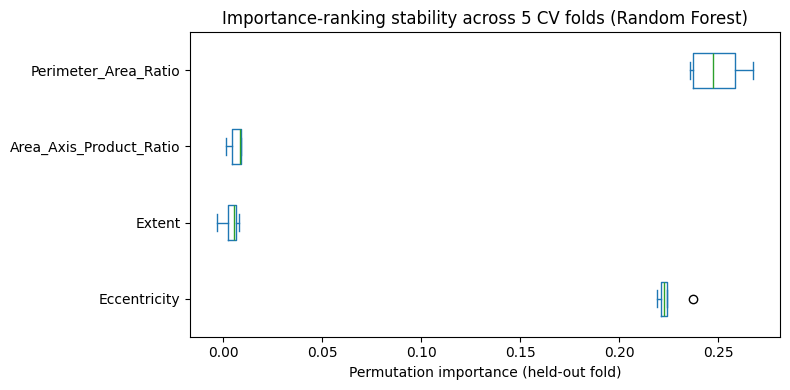

In [110]:
stability = pd.DataFrame({
    'Mean importance': fold_imp.mean(axis=1),
    'Std across folds': fold_imp.std(axis=1),
    'Mean rank':       fold_rank.mean(axis=1),
    'Rank range':      fold_rank.min(axis=1).astype(str) + " - " + fold_rank.max(axis=1).astype(str),
}).sort_values('Mean rank')
display(stability.round(4))

pair_rho = [spearmanr(fold_rank[a], fold_rank[b])[0] for a, b in combinations(fold_rank.columns, 2)]
print("Mean pairwise Spearman correlation of rankings between folds:", round(np.nanmean(pair_rho), 3))

fold_imp.T.plot(kind='box', figsize=(8, 4), vert=False)
plt.xlabel("Permutation importance (held-out fold)")
plt.title("Importance-ranking stability across 5 CV folds (Random Forest)")
plt.tight_layout()
plt.show()

In [111]:
eng_cols = list(X_train.columns)
removal_sets = {'All 4': eng_cols}
for c in eng_cols:
    removal_sets[f'Drop {c}'] = [f for f in eng_cols if f != c]

In [112]:
rem_rows = []
for set_name, cols in removal_sets.items():
    for model_name, make_model in model_factories.items():
        pipe = Pipeline([('prep', make_preprocessor(cols)), ('model', make_model())])
        cvr = cross_validate(pipe, X_train[cols], y_train, cv=cv, scoring='accuracy')
        pipe.fit(X_train[cols], y_train)
        rem_rows.append({
            'Feature set': set_name, 'Model': model_name,
            'CV Acc': cvr['test_score'].mean(), 'CV Std': cvr['test_score'].std(),
            'Test Acc': accuracy_score(y_test, pipe.predict(X_test[cols])),
        })

removal = pd.DataFrame(rem_rows)

In [113]:
cv_piv = removal.pivot(index='Feature set', columns='Model', values='CV Acc').loc[list(removal_sets)]
te_piv = removal.pivot(index='Feature set', columns='Model', values='Test Acc').loc[list(removal_sets)]

display(cv_piv.round(4))
display(cv_piv.sub(cv_piv.loc['All 4'], axis=1).drop(index='All 4').round(4))
display(te_piv.round(4))

Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
All 4,0.9236,0.9272,0.9275,0.9295
Drop Eccentricity,0.8192,0.8071,0.8189,0.8196
Drop Extent,0.9278,0.9262,0.9268,0.9291
Drop Area_Axis_Product_Ratio,0.9177,0.9203,0.9213,0.9239
Drop Perimeter_Area_Ratio,0.7884,0.7904,0.7890,0.7917


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
Drop Eccentricity,-0.1043,-0.1201,-0.1086,-0.1099
Drop Extent,0.0043,-0.0010,-0.0007,-0.0003
Drop Area_Axis_Product_Ratio,-0.0059,-0.0069,-0.0062,-0.0056
Drop Perimeter_Area_Ratio,-0.1352,-0.1368,-0.1384,-0.1378


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
All 4,0.8990,0.9081,0.9055,0.9081
Drop Eccentricity,0.7992,0.7782,0.8058,0.7940
Drop Extent,0.9121,0.9081,0.9029,0.9081
Drop Area_Axis_Product_Ratio,0.9068,0.9081,0.9081,0.9055
Drop Perimeter_Area_Ratio,0.7756,0.7717,0.7756,0.7703


### Feature-removal plots
Compare these with the permutation, SHAP and fold-stability results above.

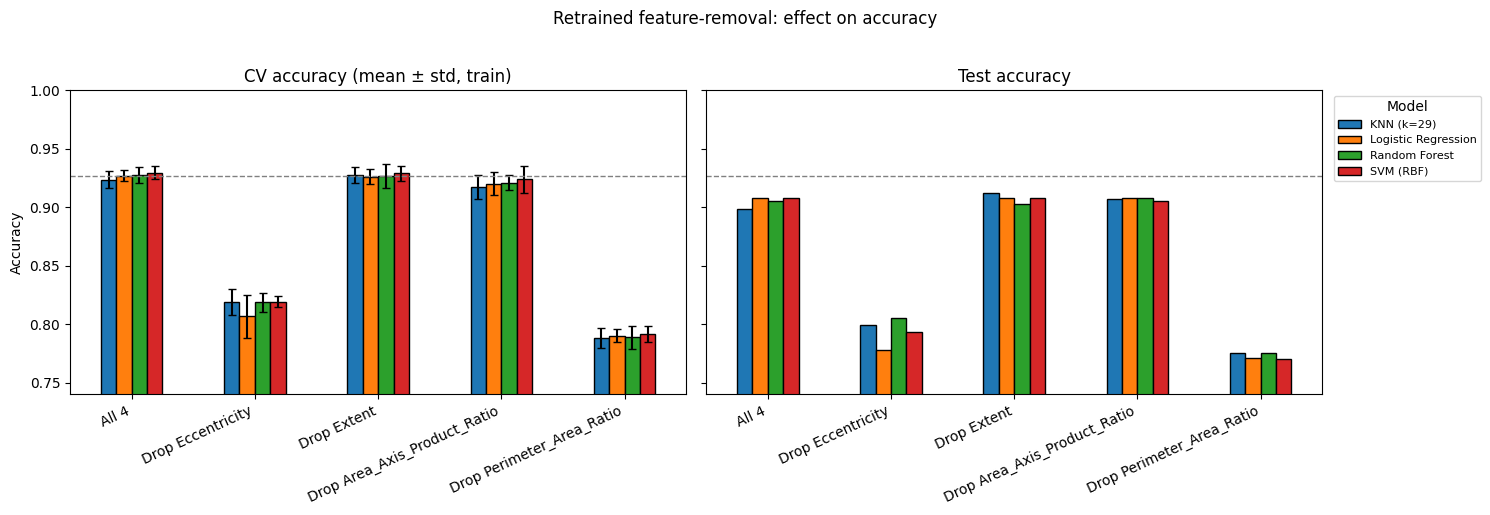

In [114]:
order = list(removal_sets)
cv_std_piv = removal.pivot(index='Feature set', columns='Model', values='CV Std').loc[order]
y_lo = min(cv_piv.min().min(), te_piv.min().min()) - 0.03

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

cv_piv.plot(kind='bar', yerr=cv_std_piv, capsize=3, edgecolor='black', ax=axes[0], legend=False)
axes[0].set_title("CV accuracy (mean ± std, train)")

te_piv.plot(kind='bar', edgecolor='black', ax=axes[1])
axes[1].set_title("Test accuracy")
axes[1].legend(title="Model", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)

for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("Accuracy")
    ax.set_ylim(y_lo, 1.0)
    ax.axhline(cv_piv.loc['All 4'].mean(), color='gray', linestyle='--', linewidth=1)  # "All 4" CV level
    ax.tick_params(axis='x', rotation=25)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')

plt.suptitle("Retrained feature-removal: effect on accuracy", y=1.02)
plt.tight_layout()
plt.show()

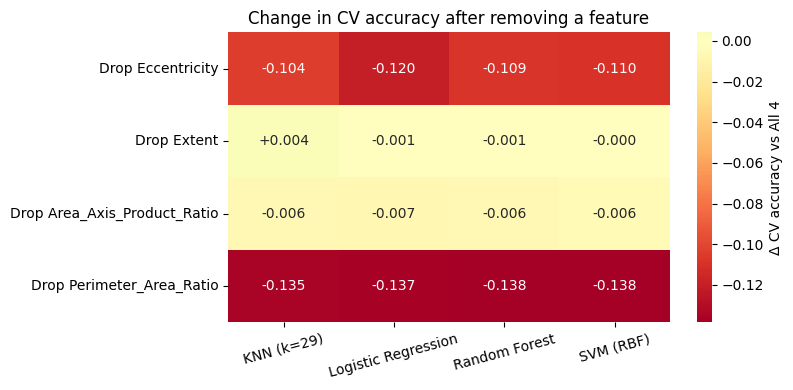

In [115]:
delta_cv = cv_piv.sub(cv_piv.loc['All 4'], axis=1).drop(index='All 4')

plt.figure(figsize=(8, 4))
sns.heatmap(delta_cv, annot=True, fmt='+.3f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Δ CV accuracy vs All 4'})
plt.title("Change in CV accuracy after removing a feature")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretation of the retrained feature removal.** Removing __ and __ reduces CV accuracy by about __
points for every model, whereas removing __ changes it by __ (within the CV standard deviation).
__ shows a small, consistent drop of about __ points.

# Answer to the Business Lens

**Important measurements:** The most consistently informative original measurements were ___.

**Overlapping measurements:** ___ shared substantial predictive information with ___.

**Recommended subset:** We recommend ___ as a candidate reduced measurement set.

**Performance trade-off:** Compared with all seven measurements, the subset changed macro-F1 by ___
percentage points and accuracy by ___ percentage points (95% CI for macro-F1: ___ to ___).

**Business implication:** The subset may simplify feature extraction, subject to confirmation that the
omitted measurements can actually be avoided.

**Limitations:** The findings concern two varieties and the available imaging conditions. The test set
was inspected in earlier experiments. Actual cost savings and performance under other conditions require
further validation.